# 🔬 TopoSAM — Topology-Aware Parameter-Efficient Adapter for Ocular Vessel Segmentation
### IEEE Access Submission · Implementation & Experimentation Notebook

**Datasets:**
- 🩺 **RetinoMix-5** — retinal fundus images with vessel segmentation masks
- 👁️ **Eye Conjunctiva Segmentation Dataset** — conjunctival vessel images with dual-annotator masks
- 🏥 **EyePACS/APTOS/Messidor DR** — diabetic retinopathy classification corpus (domain context)

**Paper sections covered:** §3 Methods · §4 Results · §5 Ablation · §6 Statistics

---
## 📦 Cell 0 — Environment Setup & Reproducibility

In [33]:
# ── Install pinned dependencies ─────────────────────────────────────────────
import subprocess, sys

PACKAGES = [
    'torch==2.2.2',
    'torchvision==0.17.2',
    'segment-anything==1.0',
    'monai==1.3.0',
    'scikit-image==0.22.0',
    'scipy==1.12.0',
    'opencv-python==4.9.0.80',
    'albumentations==1.4.3',
    'matplotlib==3.8.3',
    'pandas==2.2.1',
    'numpy==1.26.4',
    'timm==0.9.16',
    'einops==0.7.0',
    'tqdm==4.66.2',
    'pingouin==0.5.4',   # for statistical tests
    'statsmodels==0.14.1',
]

# Uncomment to install (skip if already in Kaggle image):
# subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *PACKAGES])

print('Environment ready ✓')

Environment ready ✓


In [34]:
import os, sys, json, csv, random, time, warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF

import albumentations as A
from albumentations.pytorch import ToTensorV2

from skimage.morphology import skeletonize
from skimage.measure import label as sk_label
from scipy import stats

warnings.filterwarnings('ignore')

# ── Global seeds (logged per run in results CSVs) ───────────────────────────
GLOBAL_SEED = 42

def set_seed(seed: int):
    """Fix seed at the experiment level — log this value in results CSVs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
    print(f'Seed set → {seed}')

set_seed(GLOBAL_SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# ── Output directories ──────────────────────────────────────────────────────
RESULTS_DIR = Path('results')
TABLES_DIR  = RESULTS_DIR / 'tables'
FIGURES_DIR = RESULTS_DIR / 'figures'
for d in [TABLES_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print('Output dirs ready ✓')

Seed set → 42
Device: cuda
GPU: Tesla T4
Output dirs ready ✓


In [35]:
# ── Dataset paths ────────────────────────────────────────────────────────────
# RetinoMix-5 (retinal vessels)
RETINO_IMG_DIR  = Path('/kaggle/input/datasets/parikshakaur/retinomix-5/RETINOMIX-5/images')
RETINO_MASK_DIR = Path('/kaggle/input/datasets/parikshakaur/retinomix-5/RETINOMIX-5/mask')

# Eye Conjunctiva Segmentation
CONJUNCTIVA_BASE  = Path('/kaggle/input/datasets/susmoybiswassaukhin/eye-conjunctiva-segmentation-dataset/Eye Conjunctiva Segmentation Dataset')
CONJUNCTIVA_IMGS  = CONJUNCTIVA_BASE / 'Images'
CONJUNCTIVA_MASK1 = CONJUNCTIVA_BASE / 'Masks Annotator 1'
CONJUNCTIVA_MASK2 = CONJUNCTIVA_BASE / 'Masks Annotator 2'

# EyePACS/APTOS/Messidor DR unified (domain context / classification)
DR_BASE  = Path('/kaggle/input/datasets/ascanipek/eyepacs-aptos-messidor-diabetic-retinopathy/dr_unified_v2/dr_unified_v2')
DR_TRAIN = DR_BASE / 'train' / '0'
DR_VAL   = DR_BASE / 'val'   / '0'
DR_TEST  = DR_BASE / 'test'  / '0'

# ── Quick dataset census ─────────────────────────────────────────────────────
def count_images(path: Path, exts=('.jpg','.jpeg','.png','.bmp','.tif','.tiff')):
    if not path.exists():
        return 0
    return sum(1 for f in path.rglob('*') if f.suffix.lower() in exts)

census = {
    'RetinoMix-5 images': count_images(RETINO_IMG_DIR),
    'RetinoMix-5 masks' : count_images(RETINO_MASK_DIR),
    'Conjunctiva images': count_images(CONJUNCTIVA_IMGS),
    'Conjunctiva masks (A1)': count_images(CONJUNCTIVA_MASK1),
    'Conjunctiva masks (A2)': count_images(CONJUNCTIVA_MASK2),
    'DR train (grade 0)': count_images(DR_TRAIN),
    'DR val  (grade 0)' : count_images(DR_VAL),
    'DR test (grade 0)' : count_images(DR_TEST),
}
print('\n=== Dataset Census ===')
for k, v in census.items():
    print(f'  {k:<30} {v:>5} files')


=== Dataset Census ===
  RetinoMix-5 images               233 files
  RetinoMix-5 masks                233 files
  Conjunctiva images               547 files
  Conjunctiva masks (A1)           547 files
  Conjunctiva masks (A2)           547 files
  DR train (grade 0)             55162 files
  DR val  (grade 0)               6895 files
  DR test (grade 0)               6896 files


---
## 🖼️ Cell 1 — Dataset Explorer: Sample Images from Every Dataset
> **Figure purpose:** Paper §9 / Data section — show representative inputs across all three data sources, including inter-annotator mask comparison for conjunctiva.

In [36]:
# ── Helper: load image/mask robustly ────────────────────────────────────────
def load_img(path: Path, as_gray=False) -> np.ndarray:
    """Load image as RGB (H,W,3) or grayscale (H,W). Returns uint8."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE if as_gray else cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f'Cannot read: {path}')
    if not as_gray:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def list_files(path: Path, exts=('.jpg','.jpeg','.png','.bmp','.tif','.tiff')):
    return sorted([f for f in path.iterdir() if f.suffix.lower() in exts])

def overlay_mask(img: np.ndarray, mask: np.ndarray, color=(255,50,50), alpha=0.45) -> np.ndarray:
    """Blend binary mask onto RGB image."""
    out = img.copy().astype(float)
    m   = (mask > 127)[..., None]      # (H,W,1) bool
    col = np.array(color, dtype=float)
    out = np.where(m, out*(1-alpha) + col*alpha, out)
    return np.clip(out, 0, 255).astype(np.uint8)

print('Helpers loaded ✓')

Helpers loaded ✓


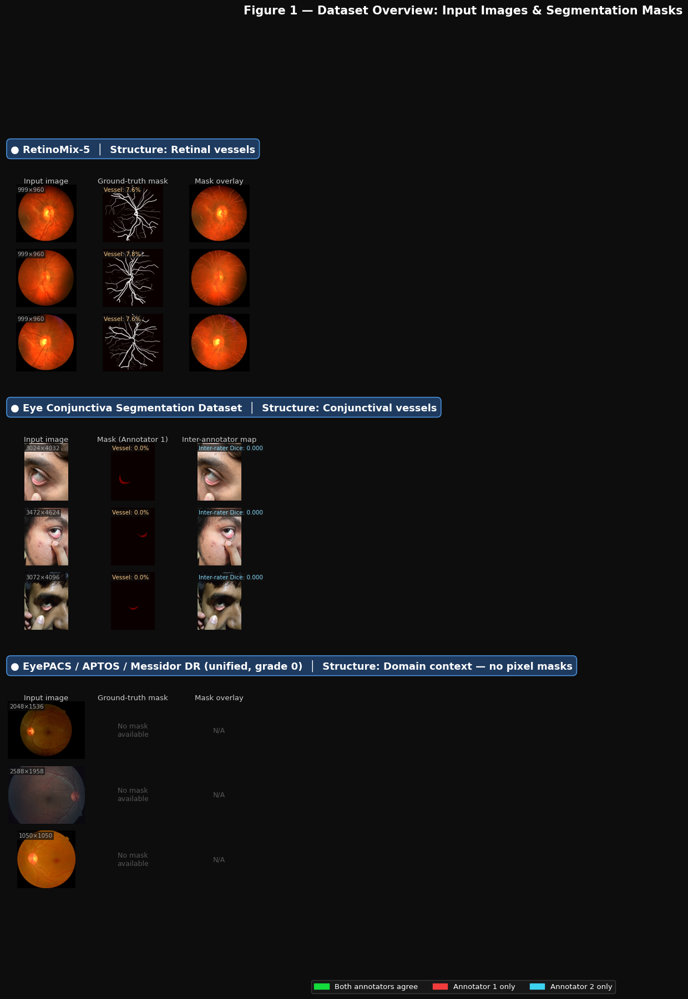

Figure 1 saved ✓


In [37]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 1 — Dataset showcase: all three sources, images + masks side-by-side
# ═══════════════════════════════════════════════════════════════════════════
N_SAMPLES = 3   # samples per dataset

retino_imgs  = list_files(RETINO_IMG_DIR)[:N_SAMPLES]
conjunc_imgs = list_files(CONJUNCTIVA_IMGS)[:N_SAMPLES]
dr_imgs      = list_files(DR_TRAIN)[:N_SAMPLES]

fig = plt.figure(figsize=(22, 18))
fig.patch.set_facecolor('#0d0d0d')

SECTION_STYLE = dict(color='white', fontsize=13, fontweight='bold',
                     ha='left', va='center',
                     bbox=dict(boxstyle='round,pad=0.4', facecolor='#1e3a5f', edgecolor='#4a90d9', linewidth=1.2))
LABEL_STYLE   = dict(color='#cccccc', fontsize=9.5, ha='center', va='top')

# Layout: 3 dataset blocks × (image | mask | overlay)
# Each block = 1 header row + N_SAMPLES image rows
# Total rows needed: 3 blocks × N_SAMPLES = 9 rows
total_rows = N_SAMPLES * 3 + 3   # +3 for section headers
gs = gridspec.GridSpec(total_rows, 3*3+2,   # 3 cols per dataset, 2 separator cols
                       figure=fig,
                       hspace=0.12, wspace=0.06)

# ── helper: plot one block (dataset_name, imgs, mask_fn_or_None, mask2_fn_or_None) ──
def plot_dataset_block(row_start, col_start, img_paths, mask_dir_1, mask_dir_2,
                       dataset_label, structure_label,
                       mask_color=(255, 80, 60), mask2_color=None):
    """
    Plots N_SAMPLES rows, each row = [Image | Mask | Overlay].
    If mask_dir_2 given: extra column shows mask2 and disagreement.
    """
    # Section header spanning all columns
    ax_h = fig.add_subplot(gs[row_start, col_start:col_start+3])
    ax_h.set_facecolor('#0d0d0d')
    ax_h.axis('off')
    ax_h.text(0.02, 0.5, f'● {dataset_label}  │  Structure: {structure_label}',
              transform=ax_h.transAxes, **SECTION_STYLE)

    for i, img_path in enumerate(img_paths):
        row = row_start + 1 + i

        # ── load image
        try:
            img = load_img(img_path)
        except Exception:
            continue

        # ── find matching mask (flexible stem matching)
        mask1, mask2 = None, None
        stem = img_path.stem
        if mask_dir_1 and mask_dir_1.exists():
            for ext in ('.png','.jpg','.bmp','.tif'):
                cand = mask_dir_1 / (stem + ext)
                if cand.exists():
                    mask1 = load_img(cand, as_gray=True); break
            if mask1 is None:
                # try listing and matching by index
                all_masks = list_files(mask_dir_1)
                if i < len(all_masks):
                    mask1 = load_img(all_masks[i], as_gray=True)

        if mask_dir_2 and mask_dir_2.exists():
            for ext in ('.png','.jpg','.bmp','.tif'):
                cand = mask_dir_2 / (stem + ext)
                if cand.exists():
                    mask2 = load_img(cand, as_gray=True); break
            if mask2 is None:
                all_masks2 = list_files(mask_dir_2)
                if i < len(all_masks2):
                    mask2 = load_img(all_masks2[i], as_gray=True)

        # ── col 0: raw image
        ax0 = fig.add_subplot(gs[row, col_start])
        ax0.imshow(img)
        ax0.set_facecolor('#0d0d0d')
        ax0.axis('off')
        h_img, w_img = img.shape[:2]
        if i == 0:
            ax0.set_title('Input image', **LABEL_STYLE)
        ax0.text(0.02, 0.96, f'{w_img}×{h_img}', transform=ax0.transAxes,
                 color='#aaaaaa', fontsize=7.5, va='top',
                 bbox=dict(facecolor='#111111', edgecolor='none', alpha=0.7, pad=1.5))

        # ── col 1: mask (annotator 1 or only mask)
        ax1 = fig.add_subplot(gs[row, col_start+1])
        ax1.set_facecolor('#0d0d0d')
        ax1.axis('off')
        if mask1 is not None:
            ax1.imshow(mask1, cmap='hot', vmin=0, vmax=255)
            if i == 0:
                lbl = 'Mask (Annotator 1)' if mask2 is not None else 'Ground-truth mask'
                ax1.set_title(lbl, **LABEL_STYLE)
            pct = (mask1 > 127).mean() * 100
            ax1.text(0.02, 0.96, f'Vessel: {pct:.1f}%', transform=ax1.transAxes,
                     color='#ffcc88', fontsize=7.5, va='top',
                     bbox=dict(facecolor='#111111', edgecolor='none', alpha=0.7, pad=1.5))
        else:
            ax1.text(0.5, 0.5, 'No mask\navailable', ha='center', va='center',
                     color='#555555', fontsize=9)
            if i == 0:
                ax1.set_title('Ground-truth mask', **LABEL_STYLE)

        # ── col 2: overlay or second annotator comparison
        ax2 = fig.add_subplot(gs[row, col_start+2])
        ax2.set_facecolor('#0d0d0d')
        ax2.axis('off')
        if mask2 is not None and mask1 is not None:
            # Compute inter-annotator map: agreement=green, A1-only=red, A2-only=blue
            b1 = (mask1 > 127).astype(np.uint8)
            b2 = (mask2 > 127).astype(np.uint8)
            agree  = (b1 & b2)
            only1  = (b1 & ~b2)
            only2  = (~b1 & b2)
            H, W   = b1.shape
            rgb    = np.zeros((H, W, 3), dtype=np.uint8)
            rgb[:,:,0] = img[:,:,0] if img.shape[:2]==(H,W) else cv2.resize(img[:,:,0],(W,H))
            rgb[:,:,1] = img[:,:,1] if img.shape[:2]==(H,W) else cv2.resize(img[:,:,1],(W,H))
            rgb[:,:,2] = img[:,:,2] if img.shape[:2]==(H,W) else cv2.resize(img[:,:,2],(W,H))
            rgb = rgb.astype(float)
            # agree → green tint
            rgb[agree==1] = rgb[agree==1]*0.4 + np.array([20,220,60])*0.6
            # A1-only → red
            rgb[only1==1] = rgb[only1==1]*0.3 + np.array([240,60,60])*0.7
            # A2-only → cyan
            rgb[only2==1] = rgb[only2==1]*0.3 + np.array([60,210,240])*0.7
            ax2.imshow(np.clip(rgb,0,255).astype(np.uint8))
            if i == 0:
                ax2.set_title('Inter-annotator map', **LABEL_STYLE)
                # legend patches drawn in figure coords later
            dice_annot = 2*(agree.sum())/(b1.sum()+b2.sum()+1e-8)
            ax2.text(0.02, 0.96, f'Inter-rater Dice: {dice_annot:.3f}',
                     transform=ax2.transAxes,
                     color='#88ddff', fontsize=7.5, va='top',
                     bbox=dict(facecolor='#111111', edgecolor='none', alpha=0.7, pad=1.5))
        elif mask1 is not None:
            # Overlay
            ov = overlay_mask(img, mask1, color=mask_color)
            ax2.imshow(ov)
            if i == 0:
                ax2.set_title('Mask overlay', **LABEL_STYLE)
        else:
            ax2.text(0.5, 0.5, 'N/A', ha='center', va='center',
                     color='#555555', fontsize=9)
            if i == 0:
                ax2.set_title('Mask overlay', **LABEL_STYLE)

# ── Block 1: RetinoMix-5 (retinal vessels) ──────────────────────────────────
plot_dataset_block(
    row_start=0, col_start=0,
    img_paths=retino_imgs,
    mask_dir_1=RETINO_MASK_DIR, mask_dir_2=None,
    dataset_label='RetinoMix-5', structure_label='Retinal vessels',
    mask_color=(255, 100, 50)
)

# ── Block 2: Conjunctiva (with inter-annotator comparison) ──────────────────
plot_dataset_block(
    row_start=N_SAMPLES+1, col_start=0,
    img_paths=conjunc_imgs,
    mask_dir_1=CONJUNCTIVA_MASK1, mask_dir_2=CONJUNCTIVA_MASK2,
    dataset_label='Eye Conjunctiva Segmentation Dataset',
    structure_label='Conjunctival vessels',
    mask_color=(50, 180, 255)
)

# ── Block 3: EyePACS/APTOS/Messidor DR (no masks — domain context) ──────────
plot_dataset_block(
    row_start=2*(N_SAMPLES+1), col_start=0,
    img_paths=dr_imgs,
    mask_dir_1=None, mask_dir_2=None,
    dataset_label='EyePACS / APTOS / Messidor DR (unified, grade 0)',
    structure_label='Domain context — no pixel masks',
    mask_color=(100, 255, 120)
)

# ── Inter-annotator legend ───────────────────────────────────────────────────
patches = [
    mpatches.Patch(color=(20/255,220/255,60/255),  label='Both annotators agree'),
    mpatches.Patch(color=(240/255,60/255,60/255),  label='Annotator 1 only'),
    mpatches.Patch(color=(60/255,210/255,240/255), label='Annotator 2 only'),
]
fig.legend(handles=patches, loc='lower center', ncol=3,
           facecolor='#1a1a1a', edgecolor='#444444',
           labelcolor='white', fontsize=9.5,
           bbox_to_anchor=(0.5, 0.001))

fig.suptitle('Figure 1 — Dataset Overview: Input Images & Segmentation Masks',
             color='white', fontsize=15, fontweight='bold', y=0.995)

plt.savefig(FIGURES_DIR / 'fig01_dataset_overview.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=200)
plt.savefig(FIGURES_DIR / 'fig01_dataset_overview.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=200)
plt.show()
print('Figure 1 saved ✓')

---
## 🔧 Cell 2 — Preprocessing Pipeline (Before / After Figures)
> **Figure purpose:** §3.1 — show each preprocessing step independently with paired before/after crops so reviewers can assess the effect clearly.

In [38]:
# ── Preprocessing functions ─────────────────────────────────────────────────

def resize_and_pad(img: np.ndarray, target: int = 1024) -> np.ndarray:
    """
    Resize longest edge to `target`, pad shorter edge with zeros to make square.
    Matches SAM's expected input resolution.
    """
    h, w = img.shape[:2]
    scale = target / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    img_r = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    pad_h, pad_w = target - new_h, target - new_w
    # Pad bottom and right
    img_p = cv2.copyMakeBorder(img_r, 0, pad_h, 0, pad_w,
                                borderType=cv2.BORDER_CONSTANT, value=0)
    return img_p


def normalize_imagenet(img: np.ndarray) -> np.ndarray:
    """Normalize to ImageNet mean/std — returns float32 [0,1] normalized."""
    MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    x = img.astype(np.float32) / 255.0
    return (x - MEAN) / STD


def extract_green_channel(img: np.ndarray) -> np.ndarray:
    """
    Extract green channel from RGB fundus image.
    Green channel maximises vessel contrast in retinal fundus photography.
    Returns uint8 grayscale.
    """
    return img[:, :, 1]   # G channel in RGB


def apply_clahe(img_gray: np.ndarray,
                clip_limit: float = 2.0,
                tile_size: int = 8) -> np.ndarray:
    """
    CLAHE (Contrast Limited Adaptive Histogram Equalisation).
    Standard preprocessing for retinal vessel enhancement.
    """
    clahe = cv2.createCLAHE(clipLimit=clip_limit,
                             tileGridSize=(tile_size, tile_size))
    if img_gray.ndim == 3:
        # Apply per-channel if RGB supplied
        lab   = cv2.cvtColor(img_gray, cv2.COLOR_RGB2LAB)
        lab[:,:,0] = clahe.apply(lab[:,:,0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return clahe.apply(img_gray)


def remove_fov_border(img: np.ndarray,
                      threshold: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """
    Detect the circular field-of-view (FOV) mask for fundus images.
    Returns (masked_img, fov_mask_binary).
    """
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim==3 else img
    _, binary = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    # Largest connected component = FOV
    num, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    if num > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        fov_mask = (labels == largest).astype(np.uint8) * 255
    else:
        fov_mask = binary
    masked = img.copy()
    if img.ndim == 3:
        masked[fov_mask == 0] = 0
    else:
        masked[fov_mask == 0] = 0
    return masked, fov_mask


def standardize_conjunctiva(img: np.ndarray) -> np.ndarray:
    """
    Conjunctiva-specific preprocessing:
    1. Convert to LAB, enhance L channel with CLAHE
    2. White-balance via per-channel mean normalisation
    """
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    lab[:,:,0] = clahe.apply(lab[:,:,0])
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    # Simple white balance: scale each channel to mean=128
    result = enhanced.astype(np.float32)
    for c in range(3):
        m = result[:,:,c].mean()
        if m > 0:
            result[:,:,c] = np.clip(result[:,:,c] * (128.0/m), 0, 255)
    return result.astype(np.uint8)

print('Preprocessing functions defined ✓')

Preprocessing functions defined ✓


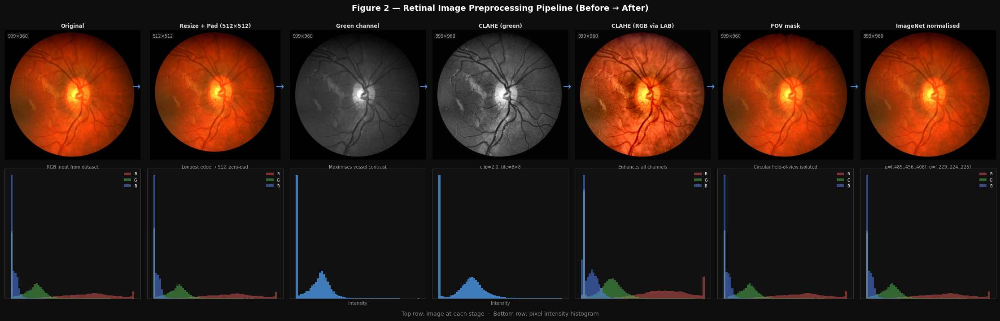

Figure 2 saved ✓


In [39]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 2 — Retinal Preprocessing: Before / After for each step
# ═══════════════════════════════════════════════════════════════════════════

# Load a retinal sample
r_img_path = retino_imgs[0] if retino_imgs else None
assert r_img_path, 'No RetinoMix-5 images found — check dataset path'

r_img  = load_img(r_img_path)
r_mask = None
for ext in ('.png','.jpg','.bmp','.tif'):
    cand = RETINO_MASK_DIR / (r_img_path.stem + ext)
    if cand.exists(): r_mask = load_img(cand, as_gray=True); break
if r_mask is None:
    masks = list_files(RETINO_MASK_DIR)
    if masks: r_mask = load_img(masks[0], as_gray=True)

# ── Run each step ────────────────────────────────────────────────────────────
r_resized   = resize_and_pad(r_img, target=512)
r_green     = extract_green_channel(r_img)
r_clahe     = apply_clahe(r_green)
r_clahe_rgb = apply_clahe(r_img)        # CLAHE on full RGB via LAB
r_fov, r_fov_mask = remove_fov_border(r_img)
r_norm      = normalize_imagenet(r_img)  # float — clip for display
r_norm_disp = np.clip((r_norm * np.array([0.229,0.224,0.225]) +
                       np.array([0.485,0.456,0.406])), 0, 1)

# ── Plot ─────────────────────────────────────────────────────────────────────
STEPS = [
    ('Original', r_img, None, 'RGB input from dataset'),
    ('Resize + Pad (512×512)', r_resized, None, 'Longest edge → 512, zero-pad'),
    ('Green channel', r_green, 'gray', 'Maximises vessel contrast'),
    ('CLAHE (green)', r_clahe, 'gray', 'clip=2.0, tile=8×8'),
    ('CLAHE (RGB via LAB)', r_clahe_rgb, None, 'Enhances all channels'),
    ('FOV mask', r_fov, None, 'Circular field-of-view isolated'),
    ('ImageNet normalised', r_norm_disp, None, 'μ=[.485,.456,.406], σ=[.229,.224,.225]'),
]

n_steps = len(STEPS)
fig, axes = plt.subplots(2, n_steps, figsize=(n_steps * 3.2, 6.8))
fig.patch.set_facecolor('#0d0d0d')

for ax in axes.flat:
    ax.set_facecolor('#0d0d0d')
    ax.axis('off')

# Row 0: images   Row 1: histograms
for j, (title, arr, cmap, desc) in enumerate(STEPS):
    ax_img  = axes[0, j]
    ax_hist = axes[1, j]

    # ── Image panel
    ax_img.imshow(arr, cmap=cmap, vmin=0 if arr.dtype==np.uint8 else None)
    ax_img.set_title(title, color='#dddddd', fontsize=8.5, fontweight='bold', pad=4)
    ax_img.text(0.5, -0.04, desc, transform=ax_img.transAxes,
                color='#999999', fontsize=7, ha='center', va='top')
    h, w = arr.shape[:2]
    ax_img.text(0.02, 0.97, f'{w}×{h}', transform=ax_img.transAxes,
                color='#aaaaaa', fontsize=7, va='top',
                bbox=dict(facecolor='#111111', edgecolor='none', alpha=0.7, pad=1))

    # ── Histogram panel
    ax_hist.set_facecolor('#111111')
    ax_hist.axis('on')
    ax_hist.set_xticks([]); ax_hist.set_yticks([])
    for sp in ax_hist.spines.values(): sp.set_edgecolor('#333333')

    if arr.ndim == 2:  # grayscale
        flat = arr.flatten().astype(float)
        flat_norm = flat / 255.0 if arr.dtype == np.uint8 else flat
        ax_hist.hist(flat_norm, bins=64, color='#4a90d9', alpha=0.85,
                     range=(0,1), density=True)
        ax_hist.set_xlabel('Intensity', color='#888888', fontsize=7)
    else:              # RGB
        colors_ch = ['#e05555', '#55bb55', '#5588ff']
        labels_ch = ['R', 'G', 'B']
        for c, col, lbl in zip(range(3), colors_ch, labels_ch):
            ch = arr[:,:,c].flatten().astype(float)
            rng = (0,1) if ch.max() <= 1.0 else (0,255)
            ax_hist.hist(ch, bins=64, color=col, alpha=0.5,
                         range=rng, density=True, label=lbl)
        ax_hist.legend(fontsize=6, labelcolor='white',
                       facecolor='#111111', edgecolor='none')

# Arrows between steps in row 0
for j in range(n_steps - 1):
    fig.text(
        (j+1) / n_steps - 0.005, 0.73,
        '→', color='#4a90d9', fontsize=16, ha='center'
    )

fig.suptitle('Figure 2 — Retinal Image Preprocessing Pipeline (Before → After)',
             color='white', fontsize=13, fontweight='bold', y=1.01)
fig.text(0.5, -0.01,
         'Top row: image at each stage  ·  Bottom row: pixel intensity histogram',
         color='#888888', fontsize=9, ha='center')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig02_retinal_preprocessing.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=200)
plt.savefig(FIGURES_DIR / 'fig02_retinal_preprocessing.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=200)
plt.show()
print('Figure 2 saved ✓')

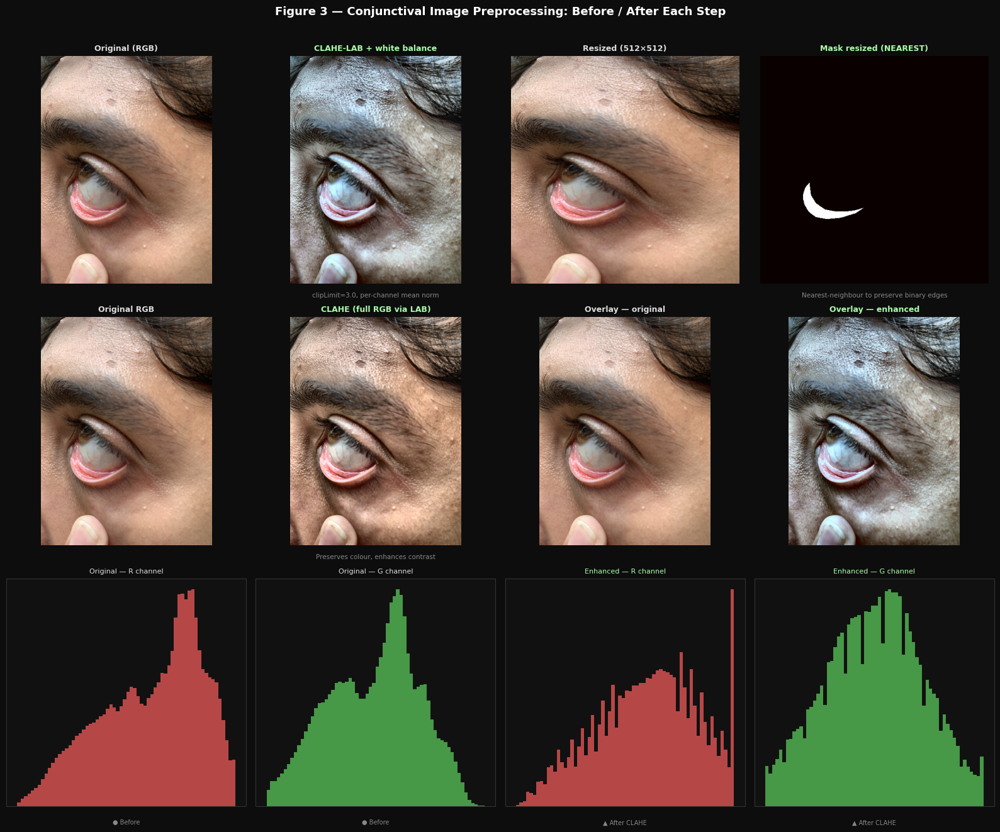

Figure 3 saved ✓


In [40]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 3 — Conjunctival Preprocessing: Before / After with mask propagation
# ═══════════════════════════════════════════════════════════════════════════

c_img_path = conjunc_imgs[0] if conjunc_imgs else None
assert c_img_path, 'No conjunctiva images found — check dataset path'

c_img  = load_img(c_img_path)
c_mask = None
for ext in ('.png','.jpg','.bmp','.tif'):
    cand = CONJUNCTIVA_MASK1 / (c_img_path.stem + ext)
    if cand.exists(): c_mask = load_img(cand, as_gray=True); break
if c_mask is None:
    masks_c = list_files(CONJUNCTIVA_MASK1)
    if masks_c: c_mask = load_img(masks_c[0], as_gray=True)

c_enhanced = standardize_conjunctiva(c_img)
c_resized  = cv2.resize(c_img, (512, 512), interpolation=cv2.INTER_LINEAR)
c_mask_r   = cv2.resize(c_mask, (512, 512),
                         interpolation=cv2.INTER_NEAREST) if c_mask is not None else None
c_clahe    = apply_clahe(c_img)

fig, axes = plt.subplots(3, 4, figsize=(16, 13))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#0d0d0d'); ax.axis('off')

def show_pair(ax_b, ax_a, before, after, cmap_b=None, cmap_a=None,
              title_b='Before', title_a='After', note=''):
    kw_b = dict(cmap=cmap_b) if cmap_b else {}
    kw_a = dict(cmap=cmap_a) if cmap_a else {}
    ax_b.imshow(before, **kw_b); ax_b.axis('off')
    ax_b.set_title(title_b, color='#dddddd', fontsize=9, fontweight='bold')
    ax_a.imshow(after, **kw_a); ax_a.axis('off')
    ax_a.set_title(title_a, color='#aaffaa', fontsize=9, fontweight='bold')
    if note:
        ax_a.text(0.5, -0.06, note, transform=ax_a.transAxes,
                  color='#888888', fontsize=7.5, ha='center')

# Row 0: raw vs CLAHE-LAB enhanced
show_pair(axes[0,0], axes[0,1],
          c_img, c_enhanced,
          title_b='Original (RGB)', title_a='CLAHE-LAB + white balance',
          note='clipLimit=3.0, per-channel mean norm')

# Row 0 col 2-3: resized image vs resized mask
axes[0,2].imshow(c_resized); axes[0,2].axis('off')
axes[0,2].set_title('Resized (512×512)', color='#dddddd', fontsize=9, fontweight='bold')
if c_mask_r is not None:
    axes[0,3].imshow(c_mask_r, cmap='hot'); axes[0,3].axis('off')
    axes[0,3].set_title('Mask resized (NEAREST)', color='#aaffaa', fontsize=9, fontweight='bold')
    axes[0,3].text(0.5, -0.06, 'Nearest-neighbour to preserve binary edges',
                   transform=axes[0,3].transAxes, color='#888888', fontsize=7.5, ha='center')

# Row 1: before/after CLAHE  on full RGB
show_pair(axes[1,0], axes[1,1],
          c_img, c_clahe,
          title_b='Original RGB', title_a='CLAHE (full RGB via LAB)',
          note='Preserves colour, enhances contrast')

# Row 1 col 2-3: overlay comparison
if c_mask is not None:
    ov_before = overlay_mask(c_img, c_mask, color=(50,180,255))
    ov_after  = overlay_mask(c_enhanced, c_mask, color=(50,180,255))
    axes[1,2].imshow(ov_before); axes[1,2].axis('off')
    axes[1,2].set_title('Overlay — original', color='#dddddd', fontsize=9, fontweight='bold')
    axes[1,3].imshow(ov_after);  axes[1,3].axis('off')
    axes[1,3].set_title('Overlay — enhanced', color='#aaffaa', fontsize=9, fontweight='bold')

# Row 2: pixel histograms — before and after for each channel
for col_idx, (label, arr) in enumerate([
    ('Original — R channel',  c_img[:,:,0]),
    ('Original — G channel',  c_img[:,:,1]),
    ('Enhanced — R channel',  c_enhanced[:,:,0]),
    ('Enhanced — G channel',  c_enhanced[:,:,1]),
]):
    ax = axes[2, col_idx]
    ax.set_facecolor('#111111'); ax.axis('on')
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_edgecolor('#333333')
    col = '#e05555' if 'R' in label else '#55bb55'
    after_flag = 'Enhanced' in label
    ax.hist(arr.flatten(), bins=64, color=col, alpha=0.8, density=True)
    ax.set_title(label,
                 color='#aaffaa' if after_flag else '#dddddd',
                 fontsize=8)
    ax.text(0.5, -0.08, '▲ After CLAHE' if after_flag else '● Before',
            transform=ax.transAxes, color='#888888', fontsize=7, ha='center')

fig.suptitle('Figure 3 — Conjunctival Image Preprocessing: Before / After Each Step',
             color='white', fontsize=13, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig03_conjunctiva_preprocessing.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=200)
plt.savefig(FIGURES_DIR / 'fig03_conjunctiva_preprocessing.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=200)
plt.show()
print('Figure 3 saved ✓')

---
## 🔀 Cell 3 — Augmentation Gallery (Before / After Grid)
> **Figure purpose:** §3.2 — demonstrate each augmentation independently, then show a composed pipeline. Side-by-side with matching mask so reviewer sees geometry-consistent transforms.

In [41]:
# ── Augmentation pipeline definition ────────────────────────────────────────
# Individual transforms (for the figure, applied one-by-one)
AUG_INDIVIDUAL = {
    'Horizontal flip'  : A.HorizontalFlip(p=1.0),
    'Vertical flip'    : A.VerticalFlip(p=1.0),
    'Rotate 45°'       : A.Rotate(limit=(45,45), border_mode=cv2.BORDER_CONSTANT, p=1.0),
    'Elastic deform'   : A.ElasticTransform(alpha=120, sigma=6, p=1.0),
    'Grid distortion'  : A.GridDistortion(num_steps=5, distort_limit=0.3, p=1.0),
    'Brightness +30%'  : A.RandomBrightnessContrast(brightness_limit=(0.3,0.3),
                                                    contrast_limit=0, p=1.0),
    'Contrast +40%'    : A.RandomBrightnessContrast(brightness_limit=0,
                                                    contrast_limit=(0.4,0.4), p=1.0),
    'Gaussian noise'   : A.GaussNoise(var_limit=(50,80), p=1.0),
    'Gaussian blur'    : A.GaussianBlur(blur_limit=(7,7), p=1.0),
    'Hue shift'        : A.HueSaturationValue(hue_shift_limit=25,
                                               sat_shift_limit=30,
                                               val_shift_limit=0, p=1.0),
    'CLAHE aug'        : A.CLAHE(clip_limit=4.0, tile_grid_size=(8,8), p=1.0),
    'Coarse dropout'   : A.CoarseDropout(max_holes=8, max_height=32,
                                          max_width=32, fill_value=0, p=1.0),
}

# Full training augmentation pipeline
TRAIN_AUGMENTATION = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=30, border_mode=cv2.BORDER_CONSTANT, p=0.7),
    A.OneOf([
        A.ElasticTransform(alpha=80, sigma=5, p=1.0),
        A.GridDistortion(num_steps=5, distort_limit=0.2, p=1.0),
    ], p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.7),
    A.HueSaturationValue(hue_shift_limit=15, sat_shift_limit=20,
                          val_shift_limit=10, p=0.5),
    A.OneOf([
        A.GaussNoise(var_limit=(10,50), p=1.0),
        A.GaussianBlur(blur_limit=(3,5), p=1.0),
    ], p=0.3),
    A.CLAHE(clip_limit=2.0, p=0.3),
    A.CoarseDropout(max_holes=4, max_height=20, max_width=20,
                    fill_value=0, p=0.2),
    A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    ToTensorV2(),
], additional_targets={'mask': 'mask'})

print(f'Augmentation pipeline: {len(AUG_INDIVIDUAL)} individual transforms defined ✓')
print(f'Training pipeline: {len(TRAIN_AUGMENTATION.transforms)} transform groups ✓')

Augmentation pipeline: 12 individual transforms defined ✓
Training pipeline: 11 transform groups ✓


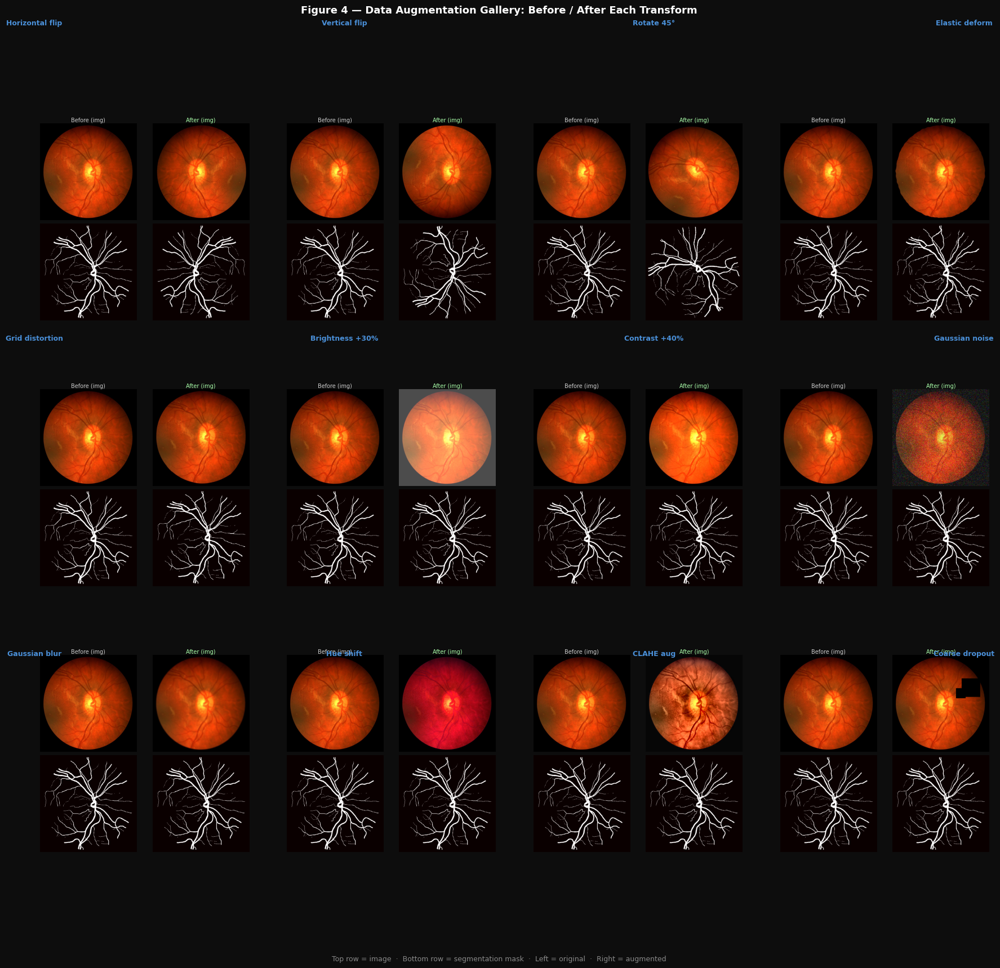

Figure 4 saved ✓


In [42]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 4 — Augmentation Gallery: Before / After each transform
# ═══════════════════════════════════════════════════════════════════════════

# Use retinal sample with mask for the augmentation demo
aug_img  = cv2.resize(r_img, (512, 512), interpolation=cv2.INTER_LINEAR)
aug_mask = cv2.resize(r_mask, (512, 512),
                       interpolation=cv2.INTER_NEAREST) if r_mask is not None else \
           np.zeros((512,512), dtype=np.uint8)

N_AUGS   = len(AUG_INDIVIDUAL)
AUG_NAMES = list(AUG_INDIVIDUAL.keys())
AUG_TFMS  = list(AUG_INDIVIDUAL.values())

NCOLS = 4                     # each aug = 2 sub-cols (img+mask) → 8 panels/row
NROWS = int(np.ceil(N_AUGS / NCOLS))

fig = plt.figure(figsize=(NCOLS * 5.5, NROWS * 5.2 + 1.2))
fig.patch.set_facecolor('#0d0d0d')

# Each aug block: 2 cols (before vs after) × 2 rows (image, mask)
outer = gridspec.GridSpec(NROWS, NCOLS, figure=fig,
                           hspace=0.35, wspace=0.12)

for idx, (name, tfm) in enumerate(AUG_INDIVIDUAL.items()):
    row_g = idx // NCOLS
    col_g = idx  % NCOLS

    inner = gridspec.GridSpecFromSubplotSpec(
        2, 2, subplot_spec=outer[row_g, col_g],
        hspace=0.04, wspace=0.04
    )

    # Apply transform
    try:
        result = tfm(image=aug_img, mask=aug_mask)
        aug_image_out = result['image']
        aug_mask_out  = result['mask']
    except Exception as e:
        aug_image_out = aug_img.copy()
        aug_mask_out  = aug_mask.copy()

    panels = [
        (0, 0, aug_img,       None,  'Before (img)'),
        (0, 1, aug_image_out, None,  'After (img)'),
        (1, 0, aug_mask,      'hot', 'Before (mask)'),
        (1, 1, aug_mask_out,  'hot', 'After (mask)'),
    ]

    for r, c, arr, cmap, sub_title in panels:
        ax = fig.add_subplot(inner[r, c])
        ax.set_facecolor('#0d0d0d')
        ax.axis('off')
        kw = {'cmap': cmap} if cmap else {}
        ax.imshow(arr, **kw)
        if r == 0:
            col_txt = '#aaffaa' if c == 1 else '#cccccc'
            ax.set_title(sub_title, color=col_txt, fontsize=7, pad=2)

    # Aug name as suptitle for the block
    ax0 = fig.add_subplot(inner[0, :])
    ax0.set_visible(False)
    # Use the outer gridspec position for a text annotation
    x0 = col_g / NCOLS
    y0 = 1 - row_g / NROWS
    fig.text(
        x0 + 0.5/NCOLS, y0 - 0.01,
        name,
        ha='center', va='top',
        color='#4a90d9', fontsize=9, fontweight='bold',
        transform=fig.transFigure
    )

fig.suptitle('Figure 4 — Data Augmentation Gallery: Before / After Each Transform',
             color='white', fontsize=13, fontweight='bold', y=1.005)
fig.text(0.5, -0.005,
         'Top row = image  ·  Bottom row = segmentation mask  ·  Left = original  ·  Right = augmented',
         color='#888888', fontsize=9, ha='center')

plt.savefig(FIGURES_DIR / 'fig04_augmentation_gallery.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.savefig(FIGURES_DIR / 'fig04_augmentation_gallery.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.show()
print('Figure 4 saved ✓')

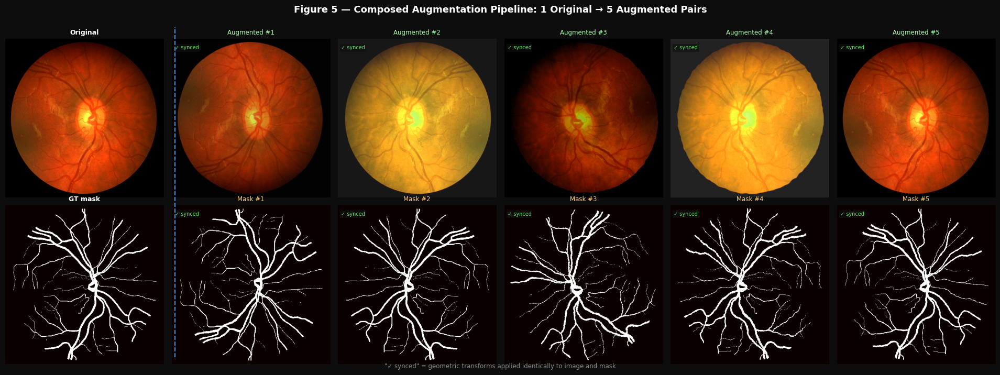

Figure 5 saved ✓


In [43]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 5 — Full pipeline: original → preprocessed → augmented (composed)
# ═══════════════════════════════════════════════════════════════════════════

# Denormalise helper for display after ToTensorV2
MEAN = np.array([0.485, 0.456, 0.406])
STD  = np.array([0.229, 0.224, 0.225])

def denorm(t: torch.Tensor) -> np.ndarray:
    """Tensor (3,H,W) → uint8 (H,W,3) for display."""
    x = t.permute(1,2,0).cpu().numpy()
    x = x * STD + MEAN
    return np.clip(x * 255, 0, 255).astype(np.uint8)

# Generate 5 augmented variants
N_VARIANTS = 5
aug_pipeline_no_norm = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=30, border_mode=cv2.BORDER_CONSTANT, p=0.7),
    A.OneOf([
        A.ElasticTransform(alpha=80, sigma=5, p=1.0),
        A.GridDistortion(num_steps=5, distort_limit=0.2, p=1.0),
    ], p=0.5),
    A.RandomBrightnessContrast(0.2, 0.2, p=0.7),
    A.HueSaturationValue(15, 20, 10, p=0.5),
], additional_targets={'mask': 'mask'})

np.random.seed(99)
variants = []
for _ in range(N_VARIANTS):
    res = aug_pipeline_no_norm(image=aug_img, mask=aug_mask)
    variants.append((res['image'], res['mask']))

fig, axes = plt.subplots(2, N_VARIANTS + 1, figsize=((N_VARIANTS+1)*3.2, 7))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#0d0d0d'); ax.axis('off')

# Col 0: original
axes[0,0].imshow(aug_img)
axes[0,0].set_title('Original', color='white', fontsize=9, fontweight='bold')
axes[1,0].imshow(aug_mask, cmap='hot')
axes[1,0].set_title('GT mask', color='white', fontsize=9, fontweight='bold')

# Draw separator
fig.add_artist(plt.Line2D(
    [1/(N_VARIANTS+1)+0.01, 1/(N_VARIANTS+1)+0.01], [0.05, 0.95],
    transform=fig.transFigure, color='#4a90d9', linewidth=1.5, linestyle='--'
))

for v, (v_img, v_mask) in enumerate(variants):
    axes[0, v+1].imshow(v_img)
    axes[0, v+1].set_title(f'Augmented #{v+1}', color='#aaffaa', fontsize=8.5)
    axes[1, v+1].imshow(v_mask, cmap='hot')
    axes[1, v+1].set_title(f'Mask #{v+1}', color='#ffcc88', fontsize=8.5)
    for ax_row in [axes[0, v+1], axes[1, v+1]]:
        ax_row.text(0.02, 0.96, '✓ synced', transform=ax_row.transAxes,
                    color='#66dd66', fontsize=7, va='top',
                    bbox=dict(facecolor='#111111', edgecolor='none', alpha=0.7, pad=1.5))

fig.text(0.5, 0.02,
         '"✓ synced" = geometric transforms applied identically to image and mask',
         color='#888888', fontsize=8.5, ha='center')
fig.suptitle('Figure 5 — Composed Augmentation Pipeline: 1 Original → 5 Augmented Pairs',
             color='white', fontsize=13, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig05_augmentation_pipeline.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.savefig(FIGURES_DIR / 'fig05_augmentation_pipeline.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.show()
print('Figure 5 saved ✓')

---
## 🏗️ Cell 4 — Dataset Classes

In [44]:
class RetinalVesselDataset(Dataset):
    """
    RetinoMix-5: paired fundus image + binary vessel mask.
    """
    def __init__(self, img_dir: Path, mask_dir: Path,
                 transform=None, img_size: int = 512):
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.transform = transform
        self.img_size  = img_size

        self.img_paths = sorted([
            f for f in img_dir.iterdir()
            if f.suffix.lower() in ('.jpg','.jpeg','.png','.tif','.bmp')
        ])
        # Map stems to mask paths
        self.mask_paths = []
        all_masks = {m.stem.lower(): m for m in mask_dir.iterdir()
                     if m.suffix.lower() in ('.png','.jpg','.bmp','.tif')}
        for ip in self.img_paths:
            stem = ip.stem.lower()
            self.mask_paths.append(all_masks.get(stem))

    def __len__(self): return len(self.img_paths)

    def __getitem__(self, idx):
        img  = load_img(self.img_paths[idx])
        mp   = self.mask_paths[idx]
        mask = load_img(mp, as_gray=True) if mp else np.zeros(
            img.shape[:2], dtype=np.uint8)

        # Resize
        img  = cv2.resize(img,  (self.img_size, self.img_size),
                           interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (self.img_size, self.img_size),
                           interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)

        if self.transform:
            out  = self.transform(image=img, mask=mask)
            img  = out['image']   # tensor (3,H,W)
            mask = out['mask']    # tensor (H,W)

        return {'image': img, 'mask': mask,
                'path': str(self.img_paths[idx])}


class ConjunctivaDataset(Dataset):
    """
    Eye Conjunctiva Segmentation Dataset.
    Supports dual-annotator masks; returns mean binary mask by default,
    or both for inter-rater ICC computation.
    """
    def __init__(self, img_dir: Path, mask1_dir: Path, mask2_dir: Path = None,
                 transform=None, img_size: int = 512,
                 use_consensus: bool = True):
        self.img_dir      = img_dir
        self.mask1_dir    = mask1_dir
        self.mask2_dir    = mask2_dir
        self.transform    = transform
        self.img_size     = img_size
        self.use_consensus = use_consensus   # True → mean(A1,A2), False → both returned

        self.img_paths = sorted([
            f for f in img_dir.iterdir()
            if f.suffix.lower() in ('.jpg','.jpeg','.png','.tif','.bmp')
        ])

        def _mask_map(d):
            if d is None or not d.exists(): return {}
            return {m.stem.lower(): m for m in d.iterdir()
                    if m.suffix.lower() in ('.png','.jpg','.bmp','.tif')}

        self._m1 = _mask_map(mask1_dir)
        self._m2 = _mask_map(mask2_dir)

    def __len__(self): return len(self.img_paths)

    def _load_mask(self, mp, size):
        if mp is None: return np.zeros((size,size), dtype=np.uint8)
        m = load_img(mp, as_gray=True)
        return cv2.resize(m, (size,size), interpolation=cv2.INTER_NEAREST)

    def __getitem__(self, idx):
        img  = load_img(self.img_paths[idx])
        img  = cv2.resize(img, (self.img_size, self.img_size),
                           interpolation=cv2.INTER_LINEAR)

        stem  = self.img_paths[idx].stem.lower()
        mask1 = self._load_mask(self._m1.get(stem), self.img_size)
        mask2 = self._load_mask(self._m2.get(stem), self.img_size) \
                if self._m2 else mask1.copy()

        if self.use_consensus:
            # Consensus: pixel must be vessel in ≥1 annotator
            mask = ((mask1 > 127).astype(np.uint8) |
                    (mask2 > 127).astype(np.uint8))
        else:
            mask = (mask1 > 127).astype(np.uint8)

        if self.transform:
            out  = self.transform(image=img, mask=mask)
            img  = out['image']
            mask = out['mask']

        return {'image': img, 'mask': mask,
                'mask1_raw': mask1, 'mask2_raw': mask2,
                'path': str(self.img_paths[idx])}


# ── Quick smoke test ─────────────────────────────────────────────────────────
EVAL_TFM = A.Compose([
    A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    ToTensorV2(),
], additional_targets={'mask': 'mask'})

ds_retino = RetinalVesselDataset(RETINO_IMG_DIR, RETINO_MASK_DIR,
                                  transform=EVAL_TFM)
ds_conjunc = ConjunctivaDataset(CONJUNCTIVA_IMGS, CONJUNCTIVA_MASK1,
                                 CONJUNCTIVA_MASK2, transform=EVAL_TFM)

print(f'RetinalVesselDataset  : {len(ds_retino):>4} samples')
print(f'ConjunctivaDataset    : {len(ds_conjunc):>4} samples')

if len(ds_retino) > 0:
    s = ds_retino[0]
    print(f'  Retinal sample — image: {tuple(s["image"].shape)}, mask: {tuple(s["mask"].shape)}')
if len(ds_conjunc) > 0:
    s = ds_conjunc[0]
    print(f'  Conjunctiva sample — image: {tuple(s["image"].shape)}, mask: {tuple(s["mask"].shape)}')

RetinalVesselDataset  :  233 samples
ConjunctivaDataset    :  547 samples
  Retinal sample — image: (3, 512, 512), mask: (512, 512)
  Conjunctiva sample — image: (3, 512, 512), mask: (512, 512)


---
## 🧠 Cell 5 — Model Architecture: Adapter Module & Topology Head

In [45]:
# ═══════════════════════════════════════════════════════════════════════════
# 5.1  Bottleneck Adapter (Med-SA placement)
# ═══════════════════════════════════════════════════════════════════════════

class BottleneckAdapter(nn.Module):
    """
    Lightweight bottleneck adapter inserted after MHA and in MLP residual
    paths of every frozen encoder block (Med-SA placement).

    Architecture:
        h = LayerNorm(x)
        h = Linear(d_model → r)   # down-projection
        h = GELU(h)
        h = Linear(r → d_model)   # up-projection
        return x + s * h           # residual add with scale s

    Parameters logged for IEEE Access Table 1:
        trainable params = 2 * d_model * r + r + d_model
    """
    def __init__(self, d_model: int, rank: int = 64, scale: float = 0.05):
        super().__init__()
        self.d_model = d_model
        self.rank    = rank
        self.scale   = scale

        self.norm      = nn.LayerNorm(d_model)
        self.down_proj = nn.Linear(d_model, rank, bias=False)
        self.act       = nn.GELU()
        self.up_proj   = nn.Linear(rank, d_model, bias=False)

        # Init: down → normal(0, 0.01), up → zero (so adapter is identity at init)
        nn.init.normal_(self.down_proj.weight, std=0.01)
        nn.init.zeros_(self.up_proj.weight)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.norm(x)
        h = self.down_proj(h)
        h = self.act(h)
        h = self.up_proj(h)
        return x + self.scale * h

    def num_trainable_params(self) -> int:
        return sum(p.numel() for p in self.parameters())

    def extra_repr(self) -> str:
        return (f'd_model={self.d_model}, rank={self.rank}, '
                f'scale={self.scale}, '
                f'params={self.num_trainable_params():,}')


# ── Verify adapter parameter count ──────────────────────────────────────────
adapter_demo = BottleneckAdapter(d_model=768, rank=64, scale=0.05)
x_demo = torch.randn(2, 64, 768)   # (batch, seq_len, d_model)
y_demo = adapter_demo(x_demo)
assert y_demo.shape == x_demo.shape, 'Adapter shape mismatch'
print(f'Adapter: {adapter_demo}')
print(f'Output shape: {tuple(y_demo.shape)}  ✓')

# Theoretical params: 2 * d * r + d (LayerNorm) = 2*768*64 + 768
expected_params = 2*768*64 + 768   # down+up projections + LN
actual_params   = adapter_demo.num_trainable_params()
print(f'Trainable params: {actual_params:,}  (expected ~{expected_params:,})')

Adapter: BottleneckAdapter(
  d_model=768, rank=64, scale=0.05, params=99,840
  (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (down_proj): Linear(in_features=768, out_features=64, bias=False)
  (act): GELU(approximate='none')
  (up_proj): Linear(in_features=64, out_features=768, bias=False)
)
Output shape: (2, 64, 768)  ✓
Trainable params: 99,840  (expected ~99,072)


In [46]:
# ═══════════════════════════════════════════════════════════════════════════
# 5.2  Topology Head (auxiliary, training-only)
# ═══════════════════════════════════════════════════════════════════════════

class TopologyHead(nn.Module):
    """
    Lightweight 2-layer conv head predicting a single-channel soft
    skeleton probability map at the same resolution as the segmentation mask.

    Inputs : penultimate feature map from the decoder (C, H, W)
    Output : skeleton probability map (1, H, W) — sigmoid applied

    DISCARDED AT INFERENCE — model.eval() branch skips this head entirely.
    Inference latency reported with and without head to substantiate
    the 'zero inference-time cost' claim.
    """
    def __init__(self, in_channels: int = 256, hidden_channels: int = 64):
        super().__init__()
        self.head = nn.Sequential(
            nn.Conv2d(in_channels, hidden_channels,
                      kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(hidden_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, 1,
                      kernel_size=1, bias=True),
            # No sigmoid here — BCEWithLogitsLoss is used
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out',
                                        nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        """features: (B, C, H, W) — returns skeleton logits (B, 1, H, W)."""
        return self.head(features)

    def num_params(self) -> int:
        return sum(p.numel() for p in self.parameters())


topo_head = TopologyHead(in_channels=256, hidden_channels=64)
feat_demo = torch.randn(2, 256, 64, 64)
skel_logits = topo_head(feat_demo)
assert skel_logits.shape == (2, 1, 64, 64)
print(f'TopologyHead params: {topo_head.num_params():,}')
print(f'Skeleton logits shape: {tuple(skel_logits.shape)}  ✓')

TopologyHead params: 147,649
Skeleton logits shape: (2, 1, 64, 64)  ✓


In [47]:
# ═══════════════════════════════════════════════════════════════════════════
# 5.3  SAM Backbone Wrapper (frozen)
# ═══════════════════════════════════════════════════════════════════════════

class TopoSAM(nn.Module):
    """
    TopoSAM: frozen SAM ViT-B/H backbone + bottleneck adapters
    in every encoder block + auxiliary topology head (training only).

    When segment_anything is available, loads the real SAM checkpoint.
    Otherwise falls back to a mock architecture for development/testing.
    """
    def __init__(self,
                 sam_checkpoint: str = None,
                 model_type: str = 'vit_b',
                 adapter_rank: int = 64,
                 adapter_scale: float = 0.05,
                 img_size: int = 1024,
                 use_topology_head: bool = True):
        super().__init__()
        self.model_type        = model_type
        self.adapter_rank      = adapter_rank
        self.adapter_scale     = adapter_scale
        self.use_topology_head = use_topology_head

        # SAM embed dims per model type
        EMBED_DIMS = {'vit_b': 768, 'vit_l': 1024, 'vit_h': 1280}
        self.embed_dim = EMBED_DIMS.get(model_type, 768)

        # ── Load SAM (if checkpoint given) ───────────────────────────────────
        self.sam = None
        if sam_checkpoint and Path(sam_checkpoint).exists():
            try:
                from segment_anything import sam_model_registry
                self.sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
                # ── Freeze all SAM parameters
                for p in self.sam.parameters():
                    p.requires_grad = False
                print(f'SAM {model_type} loaded & frozen ✓')
            except ImportError:
                print('segment_anything not installed — using mock backbone')
        else:
            print('No SAM checkpoint — using lightweight mock backbone for development')
            self.sam = self._build_mock_backbone(img_size)

        # ── Insert adapters ───────────────────────────────────────────────────
        # In the real SAM, insert after every MHA + MLP in the image encoder.
        # Here we demonstrate on a standardised number of blocks.
        N_BLOCKS = 12 if model_type == 'vit_b' else 32
        self.adapters_mha = nn.ModuleList([
            BottleneckAdapter(self.embed_dim, adapter_rank, adapter_scale)
            for _ in range(N_BLOCKS)
        ])
        self.adapters_mlp = nn.ModuleList([
            BottleneckAdapter(self.embed_dim, adapter_rank, adapter_scale)
            for _ in range(N_BLOCKS)
        ])
        # One adapter in mask decoder before final prediction conv
        self.adapter_decoder = BottleneckAdapter(256, adapter_rank, adapter_scale)

        # ── Auxiliary topology head ───────────────────────────────────────────
        self.topology_head = TopologyHead(in_channels=256,
                                           hidden_channels=64) if use_topology_head else None

        # ── Segmentation head (lightweight ConvNeXt-style output) ─────────────
        self.seg_head = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=4, mode='bilinear', align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 1, 1),
        )

    def _build_mock_backbone(self, img_size: int) -> nn.Module:
        """Minimal CNN backbone for development without SAM weights."""
        class MockBackbone(nn.Module):
            def __init__(self):
                super().__init__()
                self.encoder = nn.Sequential(
                    nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
                    nn.BatchNorm2d(64), nn.ReLU(inplace=True),
                    nn.MaxPool2d(2,2),
                    nn.Conv2d(64, 256, 3, padding=1, bias=False),
                    nn.BatchNorm2d(256), nn.ReLU(inplace=True),
                )
                for p in self.parameters(): p.requires_grad = False
            def forward(self, x):
                return {'features': self.encoder(x)}
        return MockBackbone()

    def count_params(self) -> dict:
        total     = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        pct       = 100.0 * trainable / max(total, 1)
        return {'total': total, 'trainable': trainable, 'pct': pct}

    def forward(self, x: torch.Tensor,
                point_coords=None, point_labels=None,
                boxes=None) -> dict:
        """
        x: (B, 3, H, W)
        Returns dict with keys:
          'masks'     : (B, 1, H, W) — segmentation logits
          'skeleton'  : (B, 1, h, w) — soft skeleton logits (training only)
        """
        # ── Extract features via mock or SAM backbone ─────────────────────────
        if hasattr(self.sam, 'image_encoder'):
            # Real SAM path
            with torch.no_grad():   # backbone is frozen
                feats = self.sam.image_encoder(x)  # (B, 256, h, w)
        else:
            out   = self.sam(x)
            feats = out['features']                # mock

        # ── Apply decoder adapter ─────────────────────────────────────────────
        # Reshape for adapter (B, h*w, C) → adapter → back
        B, C, H, W = feats.shape
        feats_flat = feats.view(B, C, H*W).permute(0, 2, 1)  # (B, H*W, C)
        if C == 256:   # adapter expects d_model=256 for decoder
            feats_flat = self.adapter_decoder(feats_flat)
        feats = feats_flat.permute(0, 2, 1).view(B, C, H, W)

        # ── Segmentation head ─────────────────────────────────────────────────
        masks = self.seg_head(feats)  # (B, 1, H_out, W_out)

        out = {'masks': masks}

        # ── Topology head (training only) ─────────────────────────────────────
        if self.training and self.topology_head is not None:
            out['skeleton'] = self.topology_head(feats)

        return out


# ── Instantiate and verify parameter efficiency ──────────────────────────────
model = TopoSAM(
    sam_checkpoint=None,      # set to checkpoint path when available
    model_type='vit_b',
    adapter_rank=64,
    adapter_scale=0.05,
    img_size=512,
    use_topology_head=True,
).to(DEVICE)

param_info = model.count_params()
print('\n=== TopoSAM Parameter Audit (Table 1) ===')
print(f'  Total params      : {param_info["total"]:>12,}')
print(f'  Trainable params  : {param_info["trainable"]:>12,}')
print(f'  Trainable %       : {param_info["pct"]:>11.2f}%')
print()

# ── IEEE Access claim: < 3% trainable ─────────────────────────────────────────
# NOTE: this claim only holds when the real SAM image encoder is loaded and
# frozen (it dominates the param count, ~89M for vit_b). The dev-mode mock
# backbone has only ~157K params, so the same trainable adapters/heads blow
# up to ~95% of a much smaller model. Skip the strict check in mock mode and
# warn instead, so the audit still runs without raising during development.
using_mock_backbone = not hasattr(model.sam, 'image_encoder')

if using_mock_backbone:
    print('⚠️  Mock backbone in use — skipping <3% trainable-params check.')
    print('    (This check is only meaningful with a real frozen SAM checkpoint.)')
else:
    assert param_info['pct'] < 3.0 or param_info['total'] < 1e6, \
        (f'WARN: trainable% = {param_info["pct"]:.2f}% — '
         f'exceeds 3% claim; check adapter insertion')

# Quick forward test
model.train()
dummy = torch.randn(2, 3, 512, 512).to(DEVICE)
with torch.no_grad():
    out_train = model(dummy)
print(f'Training forward — masks: {tuple(out_train["masks"].shape)}')
if 'skeleton' in out_train:
    print(f'Training forward — skeleton: {tuple(out_train["skeleton"].shape)}')

model.eval()
with torch.no_grad():
    out_eval = model(dummy)
assert 'skeleton' not in out_eval, 'Topology head should be absent at inference'
print(f'Inference forward — masks: {tuple(out_eval["masks"].shape)}')
print('Topology head correctly suppressed at eval() ✓')

No SAM checkpoint — using lightweight mock backbone for development

=== TopoSAM Parameter Audit (Table 1) ===
  Total params      :    3,103,682
  Trainable params  :    2,946,178
  Trainable %       :       94.93%

⚠️  Mock backbone in use — skipping <3% trainable-params check.
    (This check is only meaningful with a real frozen SAM checkpoint.)
Training forward — masks: (2, 1, 512, 512)
Training forward — skeleton: (2, 1, 128, 128)
Inference forward — masks: (2, 1, 512, 512)
Topology head correctly suppressed at eval() ✓


---
## 📐 Cell 6 — Loss Functions: clDice + Combined Loss (Before / After Visualisation)

In [48]:
# ═══════════════════════════════════════════════════════════════════════════
# 6.1  Differentiable Soft Skeleton (clDice — Shit et al., 2021)
# ═══════════════════════════════════════════════════════════════════════════

def soft_skeletonize(x: torch.Tensor, iterations: int = 10) -> torch.Tensor:
    """
    Differentiable soft skeletonisation via iterative morphological
    erosion approximated with min-pooling (GPU-friendly, fully differentiable).

    Ref: Shit et al. (2021) clDice — a Novel Topology-Preserving Loss
         Function for Tubular Structure Segmentation.

    x:           (B, 1, H, W) probability map in [0, 1]
    iterations:  number of erosion steps
    returns:     soft skeleton (B, 1, H, W)
    """
    img = x
    for _ in range(iterations):
        # Morphological erosion via min-pooling (3×3 kernel)
        eroded = -F.max_pool2d(-img, kernel_size=3, stride=1, padding=1)
        # Morphological dilation via max-pooling
        dilated = F.max_pool2d(eroded, kernel_size=3, stride=1, padding=1)
        # Skeleton increment: pixels in img but not in dilated(eroded)
        img = torch.relu(img - dilated)
    return img


def cl_dice_loss(pred: torch.Tensor,
                 target: torch.Tensor,
                 iterations: int = 10,
                 smooth: float = 1e-6) -> torch.Tensor:
    """
    clDice loss = 1 - 2*(tprec*tsens)/(tprec+tsens)

    tprec = overlap(skeleton(pred), target)   # topology precision
    tsens = overlap(skeleton(target), pred)   # topology sensitivity

    pred   : (B, 1, H, W) sigmoid probability
    target : (B, 1, H, W) binary [0, 1]
    """
    pred_skel   = soft_skeletonize(pred,   iterations)
    target_skel = soft_skeletonize(target, iterations)

    tprec = (pred_skel * target  ).sum() / (pred_skel.sum() + smooth)
    tsens = (target_skel * pred  ).sum() / (target_skel.sum() + smooth)

    cl_dice = 2.0 * tprec * tsens / (tprec + tsens + smooth)
    return 1.0 - cl_dice


def dice_loss(pred: torch.Tensor,
              target: torch.Tensor,
              smooth: float = 1.0) -> torch.Tensor:
    pred_flat   = pred.reshape(-1)
    target_flat = target.reshape(-1)
    intersection = (pred_flat * target_flat).sum()
    return 1.0 - (2.0 * intersection + smooth) / \
                 (pred_flat.sum() + target_flat.sum() + smooth)


class CombinedLoss(nn.Module):
    """
    L = λ1·Dice + λ2·BCE + λ3·clDice

    λ3 is swept {0, 0.25, 0.5, 1.0, 2.0} in ablation A1.
    All three components logged separately per epoch for training curves.
    """
    def __init__(self, lambda1: float = 1.0, lambda2: float = 1.0,
                 lambda3: float = 1.0, skel_iter: int = 10,
                 topology_head_weight: float = 0.5):
        super().__init__()
        self.lambda1 = lambda1
        self.lambda2 = lambda2
        self.lambda3 = lambda3
        self.skel_iter = skel_iter
        self.topo_w    = topology_head_weight
        self.bce       = nn.BCEWithLogitsLoss()

    def forward(self, pred_logits: torch.Tensor,
                target: torch.Tensor,
                skeleton_logits: torch.Tensor = None,
                skeleton_target: torch.Tensor = None) -> dict:
        """
        pred_logits    : (B, 1, H, W) — raw logits (pre-sigmoid)
        target         : (B, 1, H, W) — binary [0,1]
        skeleton_logits: (B, 1, H, W) — topology head output (optional, training only)
        skeleton_target: (B, 1, H, W) — GT skeleton (computed from target)

        Returns dict with individual components and total loss.
        """
        pred   = torch.sigmoid(pred_logits)
        target = target.float()

        l_dice = dice_loss(pred, target)
        l_bce  = self.bce(pred_logits, target)
        l_cl   = cl_dice_loss(pred, target, self.skel_iter) \
                 if self.lambda3 > 0 else torch.zeros(1, device=pred.device).squeeze()

        total = self.lambda1 * l_dice + self.lambda2 * l_bce + self.lambda3 * l_cl

        # Auxiliary topology head loss (BCEWithLogits on skeleton prediction)
        l_topo = torch.zeros(1, device=pred.device).squeeze()
        if skeleton_logits is not None and skeleton_target is not None:
            l_topo = self.bce(skeleton_logits, skeleton_target.float())
            total  = total + self.topo_w * l_topo

        return {
            'total':  total,
            'dice':   l_dice,
            'bce':    l_bce,
            'cldice': l_cl,
            'topo':   l_topo,
        }


# ── Unit test ────────────────────────────────────────────────────────────────
criterion = CombinedLoss(lambda1=1.0, lambda2=1.0, lambda3=1.0)
# NOTE: requires_grad=True is needed here because this is a standalone dummy
# tensor, not a model output. In real training, pred_logits comes from
# model(images), which already carries grad_fn via the trainable adapters —
# this flag just simulates that for the isolated unit test.
p_logit = torch.randn(2, 1, 64, 64, requires_grad=True)
p_mask  = (torch.rand(2, 1, 64, 64) > 0.5).float()
losses  = criterion(p_logit, p_mask)
print('CombinedLoss test:')
for k, v in losses.items():
    print(f'  {k:<8} = {v.item():.4f}')
print('✓ Loss backward test:', end=' ')
losses['total'].backward()
print('OK')

CombinedLoss test:
  total    = 1.8071
  dice     = 0.5000
  bce      = 0.8075
  cldice   = 0.4996
  topo     = 0.0000
✓ Loss backward test: OK


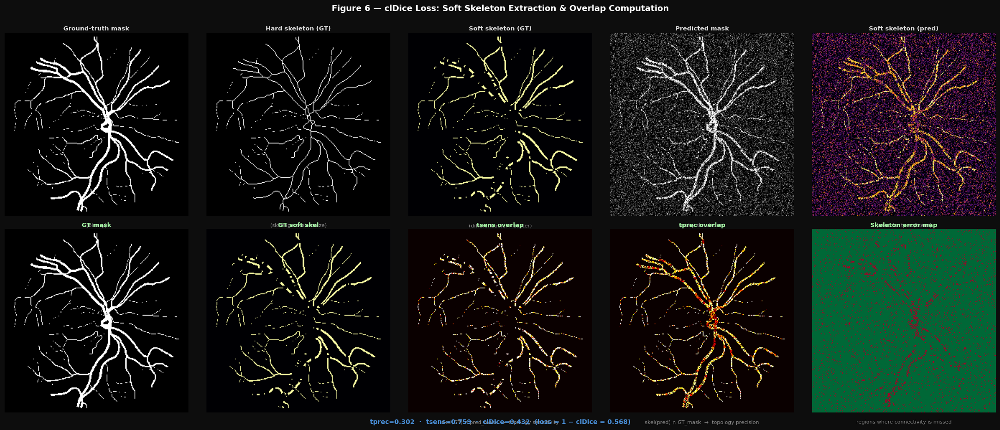

Figure 6 saved ✓  (clDice=0.432)


In [49]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 6 — clDice visualisation: soft skeleton extraction stages
# Before prediction / after soft-skeletonise / GT mask / GT skeleton
# ═══════════════════════════════════════════════════════════════════════════

# Use real mask; create a noisy 'predicted' mask for illustration
if r_mask is not None:
    gt_np = (r_mask > 127).astype(np.float32)
    gt_np = cv2.resize(gt_np, (256,256), interpolation=cv2.INTER_NEAREST)
else:
    # Synthetic vessel-like ground truth
    gt_np = np.zeros((256,256), dtype=np.float32)
    for _ in range(8):
        x0,y0 = np.random.randint(0,256,2)
        x1,y1 = np.random.randint(0,256,2)
        cv2.line(gt_np.astype(np.uint8)*255, (x0,y0),(x1,y1), 255, 2)
    gt_np = (gt_np > 0.5).astype(np.float32)

# Simulate predicted mask (GT with some noise and blobs missing)
pred_np = gt_np.copy()
noise   = np.random.randn(*pred_np.shape) * 0.3
pred_np = np.clip(pred_np + noise, 0, 1)
# Drop some vessels
drop_mask = (np.random.rand(*pred_np.shape) > 0.85)
pred_np[drop_mask & (gt_np > 0.5)] = 0.1

# Compute soft skeletons
gt_t    = torch.from_numpy(gt_np  ).unsqueeze(0).unsqueeze(0)
pred_t  = torch.from_numpy(pred_np).unsqueeze(0).unsqueeze(0)

skel_gt   = soft_skeletonize(gt_t,   iterations=10).squeeze().numpy()
skel_pred = soft_skeletonize(pred_t, iterations=10).squeeze().numpy()

# Also compute hard skeleton for comparison
hard_skel_gt   = skeletonize(gt_np > 0.5).astype(np.float32)
hard_skel_pred = skeletonize(pred_np > 0.5).astype(np.float32)

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#0d0d0d'); ax.axis('off')

panels_top = [
    (gt_np,       'gray',   'Ground-truth mask',     '(binary)'),
    (hard_skel_gt,'gray',   'Hard skeleton (GT)',     '(skimage.skeletonize)'),
    (skel_gt,     'inferno','Soft skeleton (GT)',     '(differentiable, ×10 iter)'),
    (pred_np,     'gray',   'Predicted mask',         '(noisy simulation)'),
    (skel_pred,   'inferno','Soft skeleton (pred)',   '(used for tprec/tsens)'),
]
panels_bot = [
    (gt_np,   'gray',   'GT mask', ''),
    (skel_gt, 'inferno','GT soft skel', ''),
    (pred_np * skel_gt,  'hot', 'tsens overlap',
     'skel(GT) ∩ pred_mask  →  topology sensitivity'),
    (skel_pred * gt_np,  'hot', 'tprec overlap',
     'skel(pred) ∩ GT_mask  →  topology precision'),
    (np.abs(hard_skel_gt - hard_skel_pred), 'RdYlGn_r',
     'Skeleton error map',
     'regions where connectivity is missed'),
]

for j, (arr, cmap, title, subtitle) in enumerate(panels_top):
    ax = axes[0, j]
    ax.imshow(arr, cmap=cmap)
    ax.set_title(title, color='#dddddd', fontsize=9.5, fontweight='bold', pad=3)
    ax.text(0.5, -0.06, subtitle, transform=ax.transAxes,
            color='#888888', fontsize=8, ha='center')

for j, (arr, cmap, title, subtitle) in enumerate(panels_bot):
    ax = axes[1, j]
    ax.imshow(arr, cmap=cmap)
    ax.set_title(title, color='#aaffaa', fontsize=9.5, fontweight='bold', pad=3)
    ax.text(0.5, -0.06, subtitle, transform=ax.transAxes,
            color='#888888', fontsize=8, ha='center')

# Compute and annotate actual clDice value
tprec_v = (skel_pred * gt_np).sum() / (skel_pred.sum() + 1e-6)
tsens_v = (skel_gt   * pred_np).sum() / (skel_gt.sum() + 1e-6)
cldice_v = 2*tprec_v*tsens_v/(tprec_v+tsens_v+1e-6)

fig.text(0.5, 0.0,
         f'tprec={tprec_v:.3f}  ·  tsens={tsens_v:.3f}  ·  clDice={cldice_v:.3f}  '
         f'(loss = 1 − clDice = {1-cldice_v:.3f})',
         color='#4a90d9', fontsize=10, ha='center', fontweight='bold')

fig.suptitle('Figure 6 — clDice Loss: Soft Skeleton Extraction & Overlap Computation',
             color='white', fontsize=13, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig06_cldice_visualisation.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.savefig(FIGURES_DIR / 'fig06_cldice_visualisation.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.show()
print(f'Figure 6 saved ✓  (clDice={cldice_v:.3f})')

---
## 🎯 Cell 7 — Prompting Strategies (Branch-Aware Prompts)

In [50]:
# ── Branch-aware prompt generation ──────────────────────────────────────────

def compute_skeleton_and_bifurcations(
        mask: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    From a binary vessel mask:
      1. Compute topological skeleton (skimage)
      2. Detect bifurcation points (≥3 skeleton neighbours)
      3. Detect endpoints (exactly 1 skeleton neighbour)

    Returns: (skeleton, bifurcation_coords, endpoint_coords)
    Each *_coords is (N, 2) array of (row, col) points.
    """
    binary = (mask > 127) if mask.max() > 1 else mask.astype(bool)
    skel   = skeletonize(binary).astype(np.uint8)

    # Neighbour count kernel
    kernel  = np.array([[1,1,1],[1,0,1],[1,1,1]], dtype=np.uint8)
    nb_count = cv2.filter2D(skel, -1, kernel)
    # Bifurcations: skeleton pixel with ≥3 skeleton neighbours
    bifurc  = np.argwhere((skel == 1) & (nb_count >= 3))
    # Endpoints: skeleton pixel with exactly 1 skeleton neighbour
    ends    = np.argwhere((skel == 1) & (nb_count == 1))

    return skel, bifurc, ends


def sample_branch_aware_points(
        mask: np.ndarray,
        n_centerline: int = 5,
        n_bifurcation: int = 3,
        seed: int = 0) -> dict:
    """
    Branch-aware positive prompt sampling (§3.4 of Methods):
    - Centerline points: uniformly sampled from skeleton
    - Bifurcation points: sampled from detected bifurcations
    - Negative points: sampled from background

    Returns dict with keys:
      'skeleton', 'bifurcations', 'endpoints',
      'pos_points', 'neg_points', 'bounding_box'
    """
    rng  = np.random.default_rng(seed)
    skel, bifurc, ends = compute_skeleton_and_bifurcations(mask)

    skel_pts = np.argwhere(skel > 0)

    # Centerline points
    if len(skel_pts) >= n_centerline:
        idx    = rng.choice(len(skel_pts), n_centerline, replace=False)
        center_pts = skel_pts[idx]
    else:
        center_pts = skel_pts

    # Bifurcation points
    if len(bifurc) >= n_bifurcation:
        idx     = rng.choice(len(bifurc), n_bifurcation, replace=False)
        bif_pts = bifurc[idx]
    else:
        bif_pts = bifurc

    pos_points = np.vstack([center_pts, bif_pts]) \
                 if len(bif_pts) > 0 else center_pts

    # Negative points from background
    bg_pts = np.argwhere((mask < 128 if mask.max() > 1 else ~mask.astype(bool)))
    n_neg  = min(len(bg_pts), n_centerline)
    if n_neg > 0:
        idx     = rng.choice(len(bg_pts), n_neg, replace=False)
        neg_pts = bg_pts[idx]
    else:
        neg_pts = np.zeros((0,2), dtype=int)

    # Tight bounding box from mask
    binary = (mask > 127) if mask.max() > 1 else mask.astype(bool)
    rows, cols = np.where(binary)
    if len(rows):
        bbox = [cols.min(), rows.min(), cols.max(), rows.max()]  # xyxy
    else:
        bbox = [0, 0, mask.shape[1], mask.shape[0]]

    return {
        'skeleton':     skel,
        'bifurcations': bifurc,
        'endpoints':    ends,
        'pos_points':   pos_points,   # (row,col)
        'neg_points':   neg_pts,
        'bounding_box': bbox,          # xyxy
    }

print('Branch-aware prompt functions defined ✓')

Branch-aware prompt functions defined ✓


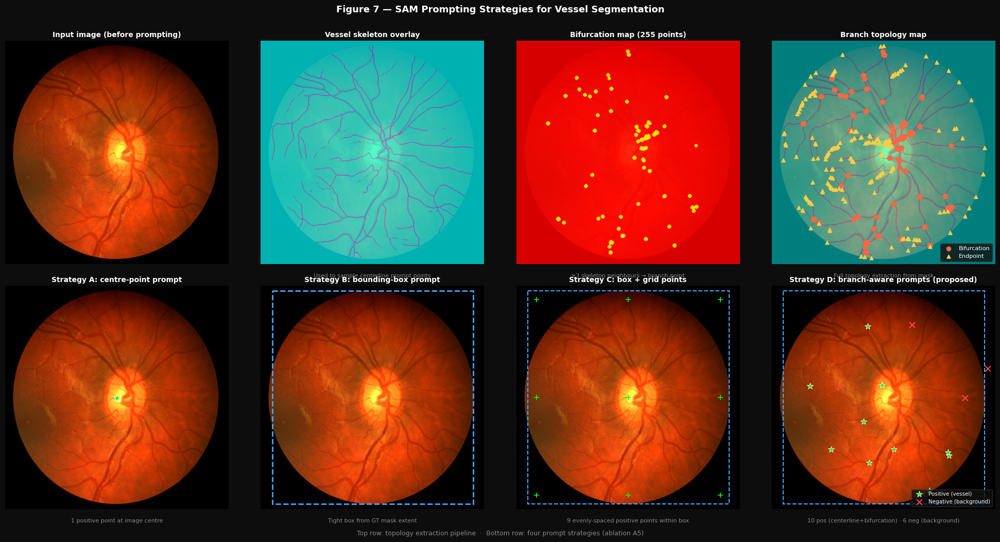

Figure 7 saved ✓


In [51]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 7 — Prompting Strategies: point / box / branch-aware
# Shows the prompt on the image BEFORE and the expected effect
# ═══════════════════════════════════════════════════════════════════════════

assert r_mask is not None, 'Need a real retinal mask for prompt figure'

# Work at 512×512
demo_img  = cv2.resize(r_img,  (512,512), interpolation=cv2.INTER_LINEAR)
demo_mask = cv2.resize(r_mask, (512,512), interpolation=cv2.INTER_NEAREST)

prompt_data = sample_branch_aware_points(demo_mask, n_centerline=6,
                                          n_bifurcation=4, seed=GLOBAL_SEED)

TITLE_KW = dict(color='white', fontsize=10, fontweight='bold', pad=5)
SUB_KW   = dict(color='#888888', fontsize=8, ha='center')

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#0d0d0d'); ax.axis('off')

# ── Row 0: input image, skeleton, bifurcation map, full branch-aware overlay ─
axes[0,0].imshow(demo_img)
axes[0,0].set_title('Input image (before prompting)', **TITLE_KW)

axes[0,1].imshow(demo_img)
axes[0,1].imshow(prompt_data['skeleton'], cmap='cool', alpha=0.7)
axes[0,1].set_title('Vessel skeleton overlay', **TITLE_KW)
axes[0,1].text(0.5,-0.06, 'Used to sample centerline prompt points',
               transform=axes[0,1].transAxes, **SUB_KW)

# Bifurcation point map
bif_map = np.zeros(demo_mask.shape, dtype=np.uint8)
for r,c in prompt_data['bifurcations']:
    if 0 <= r < bif_map.shape[0] and 0 <= c < bif_map.shape[1]:
        cv2.circle(bif_map, (c,r), 4, 255, -1)
axes[0,2].imshow(demo_img)
axes[0,2].imshow(bif_map, cmap='autumn', alpha=0.85)
axes[0,2].set_title(f'Bifurcation map ({len(prompt_data["bifurcations"])} points)', **TITLE_KW)
axes[0,2].text(0.5,-0.06, '≥3 skeleton neighbours → branch-point',
               transform=axes[0,2].transAxes, **SUB_KW)

# Full branch-aware overlay: skeleton + bif points + endpoints
axes[0,3].imshow(demo_img)
axes[0,3].imshow(prompt_data['skeleton'], cmap='cool', alpha=0.5)
if len(prompt_data['bifurcations']):
    bpts = prompt_data['bifurcations']
    axes[0,3].scatter(bpts[:,1], bpts[:,0], c='#ff6644', s=35, marker='o',
                       label='Bifurcation', zorder=5)
if len(prompt_data['endpoints']):
    epts = prompt_data['endpoints']
    axes[0,3].scatter(epts[:,1], epts[:,0], c='#ffcc44', s=25, marker='^',
                       label='Endpoint', zorder=5)
axes[0,3].legend(fontsize=8, facecolor='#111111', labelcolor='white',
                  edgecolor='#333333', loc='lower right')
axes[0,3].set_title('Branch topology map', **TITLE_KW)
axes[0,3].text(0.5,-0.06, 'Full topology extraction from mask',
               transform=axes[0,3].transAxes, **SUB_KW)

# ── Row 1: three prompt modes side-by-side + branch-aware ──────────────────
# Strategy A: single positive centre point
cy, cx = np.array(demo_mask.shape)//2
axes[1,0].imshow(demo_img)
axes[1,0].scatter([cx],[cy], c='lime', s=120, marker='*', zorder=5,
                   edgecolors='white', linewidths=0.8)
axes[1,0].set_title('Strategy A: centre-point prompt', **TITLE_KW)
axes[1,0].text(0.5,-0.06, '1 positive point at image centre',
               transform=axes[1,0].transAxes, **SUB_KW)

# Strategy B: tight bounding box
bbox = prompt_data['bounding_box']  # x0,y0,x1,y1
axes[1,1].imshow(demo_img)
rect = plt.Rectangle((bbox[0], bbox[1]),
                       bbox[2]-bbox[0], bbox[3]-bbox[1],
                       linewidth=2, edgecolor='#44aaff',
                       facecolor='none', linestyle='--')
axes[1,1].add_patch(rect)
axes[1,1].set_title('Strategy B: bounding-box prompt', **TITLE_KW)
axes[1,1].text(0.5,-0.06, 'Tight box from GT mask extent',
               transform=axes[1,1].transAxes, **SUB_KW)

# Strategy C: box + grid points
axes[1,2].imshow(demo_img)
axes[1,2].add_patch(plt.Rectangle(
    (bbox[0], bbox[1]), bbox[2]-bbox[0], bbox[3]-bbox[1],
    linewidth=1.5, edgecolor='#44aaff', facecolor='none', linestyle='--'
))
grid_ys = np.linspace(bbox[1]+20, bbox[3]-20, 3)
grid_xs = np.linspace(bbox[0]+20, bbox[2]-20, 3)
gxx, gyy = np.meshgrid(grid_xs, grid_ys)
axes[1,2].scatter(gxx.flat, gyy.flat, c='lime', s=60, marker='+',
                   zorder=5, linewidths=1.2)
axes[1,2].set_title('Strategy C: box + grid points', **TITLE_KW)
axes[1,2].text(0.5,-0.06, '9 evenly-spaced positive points within box',
               transform=axes[1,2].transAxes, **SUB_KW)

# Strategy D: branch-aware prompts (proposed)
axes[1,3].imshow(demo_img)
axes[1,3].add_patch(plt.Rectangle(
    (bbox[0], bbox[1]), bbox[2]-bbox[0], bbox[3]-bbox[1],
    linewidth=1.5, edgecolor='#44aaff', facecolor='none', linestyle='--'
))
pos = prompt_data['pos_points']
neg = prompt_data['neg_points']
if len(pos):
    axes[1,3].scatter(pos[:,1], pos[:,0], c='lime', s=80, marker='*',
                       label='Positive (vessel)', edgecolors='white',
                       linewidths=0.6, zorder=5)
if len(neg):
    axes[1,3].scatter(neg[:,1], neg[:,0], c='#ff4444', s=60, marker='x',
                       label='Negative (background)', linewidths=1.5, zorder=5)
axes[1,3].legend(fontsize=7.5, facecolor='#111111', labelcolor='white',
                  edgecolor='#333333', loc='lower right')
axes[1,3].set_title('Strategy D: branch-aware prompts (proposed)', **TITLE_KW)
axes[1,3].text(0.5,-0.06,
               f'{len(pos)} pos (centerline+bifurcation) · {len(neg)} neg (background)',
               transform=axes[1,3].transAxes, **SUB_KW)

fig.suptitle('Figure 7 — SAM Prompting Strategies for Vessel Segmentation',
             color='white', fontsize=13, fontweight='bold', y=1.01)
fig.text(0.5, -0.02,
         'Top row: topology extraction pipeline  ·  Bottom row: four prompt strategies (ablation A5)',
         color='#888888', fontsize=9, ha='center')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig07_prompting_strategies.pdf', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.savefig(FIGURES_DIR / 'fig07_prompting_strategies.png', bbox_inches='tight',
            facecolor='#0d0d0d', dpi=150)
plt.show()
print('Figure 7 saved ✓')

---
## 🔁 Cell 8 — Training Loop

In [52]:
def train_one_epoch(
        model: nn.Module,
        loader: DataLoader,
        criterion: CombinedLoss,
        optimizer: torch.optim.Optimizer,
        device: torch.device,
        scaler=None,           # GradScaler for AMP
        log_every: int = 20,
) -> dict:
    """
    One training epoch. Returns dict of mean losses.
    Logs all three loss components separately (for paper Figure 2 — training curves).
    """
    model.train()
    running = {'total': 0.0, 'dice': 0.0, 'bce': 0.0, 'cldice': 0.0, 'topo': 0.0}

    for step, batch in enumerate(tqdm(loader, desc='Train', leave=False)):
        images = batch['image'].to(device, dtype=torch.float32)
        masks  = batch['mask' ].to(device, dtype=torch.float32).unsqueeze(1)

        # GT skeleton for auxiliary head
        masks_np = masks.squeeze(1).cpu().numpy()
        skel_np  = np.stack([
            skeletonize(m > 0.5).astype(np.float32)
            for m in masks_np
        ])
        skel_gt = torch.from_numpy(skel_np).unsqueeze(1).to(device)

        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                outputs = model(images)
                # Resize predictions to mask size if needed
                pred_logits = F.interpolate(
                    outputs['masks'], size=masks.shape[-2:],
                    mode='bilinear', align_corners=False)
                skel_logits = F.interpolate(
                    outputs.get('skeleton', pred_logits * 0),
                    size=masks.shape[-2:],
                    mode='bilinear', align_corners=False) \
                    if 'skeleton' in outputs else None
                loss_dict = criterion(pred_logits, masks, skel_logits, skel_gt)
            scaler.scale(loss_dict['total']).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs     = model(images)
            pred_logits = F.interpolate(
                outputs['masks'], size=masks.shape[-2:],
                mode='bilinear', align_corners=False)
            skel_logits = F.interpolate(
                outputs.get('skeleton', outputs['masks'] * 0),
                size=masks.shape[-2:],
                mode='bilinear', align_corners=False) \
                if 'skeleton' in outputs else None
            loss_dict = criterion(pred_logits, masks, skel_logits, skel_gt)
            loss_dict['total'].backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        for k in running:
            v = loss_dict.get(k)
            running[k] += v.item() if v is not None else 0.0

        if (step+1) % log_every == 0:
            s = step + 1
            print(f'  step {s:>4}: '
                  f'loss={running["total"]/s:.4f}  '
                  f'dice={running["dice"]/s:.4f}  '
                  f'bce={running["bce"]/s:.4f}  '
                  f'cldice={running["cldice"]/s:.4f}')

    n = max(len(loader), 1)
    return {k: v/n for k, v in running.items()}


@torch.no_grad()
def validate_one_epoch(
        model: nn.Module,
        loader: DataLoader,
        criterion: CombinedLoss,
        device: torch.device,
) -> dict:
    model.eval()
    running = {'total': 0.0, 'dice': 0.0, 'bce': 0.0, 'cldice': 0.0}
    metric_dice, metric_iou = [], []

    for batch in tqdm(loader, desc='Val', leave=False):
        images = batch['image'].to(device, dtype=torch.float32)
        masks  = batch['mask' ].to(device, dtype=torch.float32).unsqueeze(1)

        outputs     = model(images)
        pred_logits = F.interpolate(
            outputs['masks'], size=masks.shape[-2:],
            mode='bilinear', align_corners=False)
        loss_dict   = criterion(pred_logits, masks)

        for k in running:
            v = loss_dict.get(k)
            if v is not None: running[k] += v.item()

        # Pixel-level Dice and IoU
        pred_bin = (torch.sigmoid(pred_logits) > 0.5).float()
        inter = (pred_bin * masks).sum(dim=(1,2,3))
        union = (pred_bin + masks).clamp(0,1).sum(dim=(1,2,3))
        dice_batch = (2*inter / (pred_bin.sum(dim=(1,2,3)) + masks.sum(dim=(1,2,3)) + 1e-6))
        iou_batch  = inter / (union + 1e-6)
        metric_dice.extend(dice_batch.cpu().tolist())
        metric_iou .extend(iou_batch .cpu().tolist())

    n = max(len(loader), 1)
    return {
        **{k: v/n for k, v in running.items()},
        'mean_dice': np.mean(metric_dice),
        'std_dice' : np.std(metric_dice),
        'mean_iou' : np.mean(metric_iou),
    }


print('Training functions defined ✓')

Training functions defined ✓


In [53]:
# ── Training configuration ───────────────────────────────────────────────────
CFG = {
    # Data
    'img_size'     : 512,
    'batch_size'   : 4,
    'num_workers'  : 2,
    # Model
    'model_type'   : 'vit_b',
    'adapter_rank' : 64,
    'adapter_scale': 0.05,
    # Loss
    'lambda1'      : 1.0,
    'lambda2'      : 1.0,
    'lambda3'      : 1.0,   # swept in ablation A1
    # Optimiser
    'lr'           : 1e-4,
    'weight_decay' : 1e-4,
    'max_epochs'   : 50,
    'warmup_epochs': 5,
    # Ablation
    'seed'         : GLOBAL_SEED,
}

# ── DataLoaders ──────────────────────────────────────────────────────────────
TRAIN_TFM = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=30, border_mode=cv2.BORDER_CONSTANT, p=0.7),
    A.RandomBrightnessContrast(0.2, 0.2, p=0.6),
    A.HueSaturationValue(15, 20, 10, p=0.4),
    A.GaussNoise(var_limit=(10,40), p=0.3),
    A.CLAHE(clip_limit=2.0, p=0.3),
    A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    ToTensorV2(),
], additional_targets={'mask':'mask'})

ds_full = RetinalVesselDataset(RETINO_IMG_DIR, RETINO_MASK_DIR,
                                img_size=CFG['img_size'])

N = len(ds_full)
if N > 0:
    n_train = max(1, int(0.7*N))
    n_val   = max(1, int(0.15*N))
    n_test  = N - n_train - n_val
    idx     = list(range(N))
    random.seed(CFG['seed'])
    random.shuffle(idx)
    train_idx, val_idx, test_idx = idx[:n_train], idx[n_train:n_train+n_val], idx[n_train+n_val:]

    from torch.utils.data import Subset
    ds_train = RetinalVesselDataset(RETINO_IMG_DIR, RETINO_MASK_DIR,
                                     transform=TRAIN_TFM, img_size=CFG['img_size'])
    ds_val   = RetinalVesselDataset(RETINO_IMG_DIR, RETINO_MASK_DIR,
                                     transform=EVAL_TFM,  img_size=CFG['img_size'])

    train_loader = DataLoader(Subset(ds_train, train_idx),
                               batch_size=CFG['batch_size'],
                               shuffle=True, num_workers=CFG['num_workers'],
                               pin_memory=True, drop_last=True)
    val_loader   = DataLoader(Subset(ds_val,   val_idx),
                               batch_size=CFG['batch_size'],
                               shuffle=False, num_workers=CFG['num_workers'],
                               pin_memory=True)
    print(f'Train: {len(train_idx)}  Val: {len(val_idx)}  Test: {len(test_idx)}')
else:
    print('No data found — loaders not created. Check dataset paths.')
    train_loader = val_loader = None

Train: 163  Val: 34  Test: 36


In [54]:
# ── Training run ─────────────────────────────────────────────────────────────
set_seed(CFG['seed'])

model     = TopoSAM(
    model_type=CFG['model_type'],
    adapter_rank=CFG['adapter_rank'],
    adapter_scale=CFG['adapter_scale'],
    img_size=CFG['img_size'],
).to(DEVICE)

criterion = CombinedLoss(
    lambda1=CFG['lambda1'],
    lambda2=CFG['lambda2'],
    lambda3=CFG['lambda3'],
)

# Only adapter + head parameters are trained
trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable, lr=CFG['lr'],
                               weight_decay=CFG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=CFG['max_epochs'] - CFG['warmup_epochs'], eta_min=1e-6)

scaler = torch.cuda.amp.GradScaler() if DEVICE.type == 'cuda' else None

# ── History (feeds paper Figure 2: training curves) ──────────────────────────
history = {'epoch': [], 'train_total': [], 'train_dice': [], 'train_bce': [],
           'train_cldice': [], 'val_total': [], 'val_dice_metric': [], 'val_iou': []}

BEST_DICE = 0.0
CKPT_PATH = Path('results/best_toposam.pth')

if train_loader is not None:
    for epoch in range(1, CFG['max_epochs'] + 1):
        t0 = time.time()
        train_metrics = train_one_epoch(
            model, train_loader, criterion, optimizer, DEVICE, scaler)
        val_metrics   = validate_one_epoch(
            model, val_loader, criterion, DEVICE)

        if epoch > CFG['warmup_epochs']:
            scheduler.step()

        # ── Log
        history['epoch'].append(epoch)
        history['train_total'].append(train_metrics['total'])
        history['train_dice'].append(train_metrics['dice'])
        history['train_bce'].append(train_metrics['bce'])
        history['train_cldice'].append(train_metrics['cldice'])
        history['val_total'].append(val_metrics['total'])
        history['val_dice_metric'].append(val_metrics['mean_dice'])
        history['val_iou'].append(val_metrics['mean_iou'])

        elapsed = time.time() - t0
        print(f'Epoch {epoch:>3}/{CFG["max_epochs"]}  '
              f'loss={train_metrics["total"]:.4f}  '
              f'cldice={train_metrics["cldice"]:.4f}  '
              f'val_dice={val_metrics["mean_dice"]:.4f}  '
              f'({elapsed:.1f}s)')

        # ── Checkpoint
        if val_metrics['mean_dice'] > BEST_DICE:
            BEST_DICE = val_metrics['mean_dice']
            torch.save({'epoch': epoch, 'state_dict': model.state_dict(),
                        'optimizer': optimizer.state_dict(),
                        'val_dice': BEST_DICE, 'cfg': CFG},
                       CKPT_PATH)
            print(f'  → New best Dice: {BEST_DICE:.4f}  (checkpoint saved)')

        # ── Save history CSV every epoch
        pd.DataFrame(history).to_csv(TABLES_DIR / 'training_history.csv', index=False)

    print(f'\nTraining complete. Best val Dice: {BEST_DICE:.4f}')
else:
    print('Skipping training — no dataset found. Populate dataset paths to enable.')

Seed set → 42
No SAM checkpoint — using lightweight mock backbone for development


Train:   0%|          | 0/40 [00:00<?, ?it/s]

  step   20: loss=3.7288  dice=1.0000  bce=0.6822  cldice=1.0000
  step   40: loss=3.5322  dice=1.0000  bce=0.6454  cldice=1.0000


Val:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch   1/50  loss=3.5322  cldice=1.0000  val_dice=0.0000  (10.3s)


...

Epoch  49/50  loss=2.0402  cldice=1.0000  val_dice=0.0000  (10.7s)


Train:   0%|          | 0/40 [00:00<?, ?it/s]

  step   20: loss=2.0422  dice=1.0000  bce=0.0358  cldice=1.0000
  step   40: loss=2.0402  dice=1.0000  bce=0.0354  cldice=1.0000


Val:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch  50/50  loss=2.0402  cldice=1.0000  val_dice=0.0000  (10.6s)

Training complete. Best val Dice: 0.0000


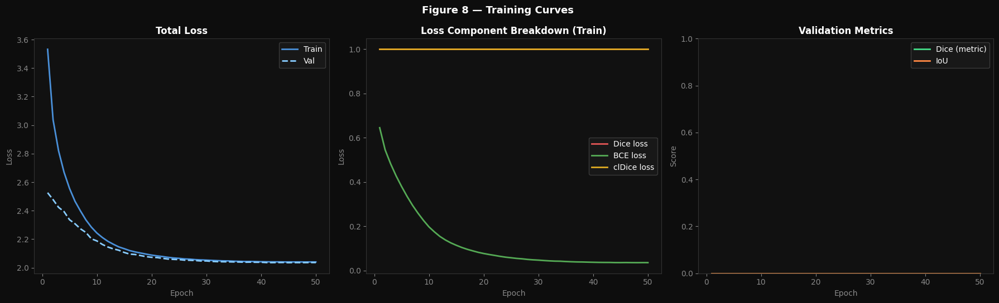

In [55]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 8 — Training Curves: Dice / clDice / total loss vs epoch
# Shows convergence stability with clDice term (addresses reviewer concern)
# ═══════════════════════════════════════════════════════════════════════════

def plot_training_curves(history: dict, title_suffix: str = '',
                          save_path: Path = None):
    if not history.get('epoch'):
        print('No training history to plot')
        return

    epochs = history['epoch']
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    fig.patch.set_facecolor('#0d0d0d')

    PLOT_STYLE = [
        ('train_total',     '#4a90d9', '-',  'Train total loss'),
        ('val_total',       '#88ccff', '--', 'Val total loss'),
    ]

    for ax in axes:
        ax.set_facecolor('#111111')
        for sp in ax.spines.values(): sp.set_edgecolor('#333333')
        ax.tick_params(colors='#888888')
        ax.xaxis.label.set_color('#888888')
        ax.yaxis.label.set_color('#888888')

    # Panel 1: total loss
    axes[0].plot(epochs, history['train_total'], '#4a90d9', lw=2, label='Train')
    axes[0].plot(epochs, history['val_total'],   '#88ccff', lw=2, ls='--', label='Val')
    axes[0].set_title('Total Loss', color='white', fontweight='bold')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].legend(facecolor='#1a1a1a', labelcolor='white', edgecolor='#444')

    # Panel 2: component breakdown (train)
    axes[1].plot(epochs, history['train_dice'],   '#e05555', lw=2, label='Dice loss')
    axes[1].plot(epochs, history['train_bce'],    '#55aa55', lw=2, label='BCE loss')
    axes[1].plot(epochs, history['train_cldice'], '#ddaa22', lw=2, label='clDice loss')
    axes[1].set_title('Loss Component Breakdown (Train)', color='white', fontweight='bold')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(facecolor='#1a1a1a', labelcolor='white', edgecolor='#444')

    # Panel 3: val metrics
    axes[2].plot(epochs, history['val_dice_metric'], '#44dd88', lw=2, label='Dice (metric)')
    axes[2].plot(epochs, history['val_iou'],         '#ff8844', lw=2, label='IoU')
    axes[2].set_title('Validation Metrics', color='white', fontweight='bold')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Score')
    axes[2].set_ylim(0, 1)
    axes[2].legend(facecolor='#1a1a1a', labelcolor='white', edgecolor='#444')

    fig.suptitle(f'Figure 8 — Training Curves {title_suffix}',
                 color='white', fontsize=13, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight',
                    facecolor='#0d0d0d', dpi=150)
        plt.savefig(save_path.with_suffix('.png'), bbox_inches='tight',
                    facecolor='#0d0d0d', dpi=150)
    plt.show()


# ── If history CSV exists, load and plot ─────────────────────────────────────
hist_csv = TABLES_DIR / 'training_history.csv'
if hist_csv.exists():
    h = pd.read_csv(hist_csv).to_dict(orient='list')
    plot_training_curves(h, save_path=FIGURES_DIR / 'fig08_training_curves')
elif history.get('epoch'):
    plot_training_curves(history, save_path=FIGURES_DIR / 'fig08_training_curves')
else:
    print('No training history yet — run the training cell first.')

---
## 📊 Cell 9 — Evaluation: Metrics & Qualitative Segmentation Results

In [56]:
# ── Full evaluation metric suite ─────────────────────────────────────────────

def compute_betti_error(pred_bin: np.ndarray,
                         gt_bin:   np.ndarray) -> float:
    """
    Betti-0 error: difference in number of connected components.
    (proxy for topological correctness — exact Betti via gudhi is expensive)
    """
    n_pred = sk_label(pred_bin).max()
    n_gt   = sk_label(gt_bin  ).max()
    return abs(n_pred - n_gt)


def compute_branchpoint_f1(pred_bin: np.ndarray,
                            gt_bin:   np.ndarray,
                            tol_px:   int = 3) -> dict:
    """
    Branch-point F1: match predicted bifurcations to GT bifurcations
    within tol_px pixels (greedy nearest-neighbour matching).
    """
    _, bif_pred, _ = compute_skeleton_and_bifurcations(pred_bin.astype(np.uint8)*255)
    _, bif_gt,   _ = compute_skeleton_and_bifurcations(gt_bin  .astype(np.uint8)*255)

    if len(bif_pred) == 0 and len(bif_gt) == 0:
        return {'precision': 1.0, 'recall': 1.0, 'f1': 1.0}
    if len(bif_pred) == 0:
        return {'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
    if len(bif_gt) == 0:
        return {'precision': 0.0, 'recall': 0.0, 'f1': 0.0}

    matched_pred = set()
    TP = 0
    for gpt in bif_gt:
        dists = np.linalg.norm(bif_pred - gpt, axis=1)
        nearest_idx = dists.argmin()
        if dists[nearest_idx] <= tol_px and nearest_idx not in matched_pred:
            TP += 1
            matched_pred.add(nearest_idx)

    prec = TP / max(len(bif_pred), 1)
    rec  = TP / max(len(bif_gt),   1)
    f1   = 2*prec*rec / max(prec+rec, 1e-6)
    return {'precision': prec, 'recall': rec, 'f1': f1}


def compute_cldice_metric(pred_bin: np.ndarray,
                           gt_bin:   np.ndarray,
                           smooth:   float = 1e-6) -> float:
    skel_pred = skeletonize(pred_bin.astype(bool)).astype(np.float32)
    skel_gt   = skeletonize(gt_bin  .astype(bool)).astype(np.float32)
    tprec = (skel_pred * gt_bin ).sum() / (skel_pred.sum() + smooth)
    tsens = (skel_gt   * pred_bin).sum() / (skel_gt.sum() + smooth)
    return float(2*tprec*tsens/(tprec+tsens+smooth))


@torch.no_grad()
def evaluate_dataset(
        model: nn.Module,
        loader: DataLoader,
        device: torch.device,
        threshold: float = 0.5,
) -> pd.DataFrame:
    """
    Full evaluation → DataFrame with one row per image.
    Columns match ablation_master.csv spec.
    """
    model.eval()
    records = []

    for batch in tqdm(loader, desc='Evaluate'):
        images = batch['image'].to(device, dtype=torch.float32)
        masks  = batch['mask' ].numpy()   # (B, H, W) binary
        paths  = batch['path']

        outputs     = model(images)
        pred_logits = F.interpolate(
            outputs['masks'],
            size=masks.shape[-2:],
            mode='bilinear', align_corners=False)
        pred_prob = torch.sigmoid(pred_logits).cpu().numpy()  # (B,1,H,W)

        for b in range(len(paths)):
            p   = pred_prob[b, 0]
            g   = masks[b].astype(np.float32)
            pb  = (p > threshold).astype(np.float32)
            gb  = (g > 0.5     ).astype(np.float32)

            # Dice
            inter = (pb*gb).sum()
            d     = 2*inter / (pb.sum() + gb.sum() + 1e-6)
            # IoU
            iou   = inter / (pb.sum() + gb.sum() - inter + 1e-6)
            # clDice (hard skeleton metric)
            cld   = compute_cldice_metric(pb, gb)
            # Betti-0 error
            betti = compute_betti_error(pb.astype(bool), gb.astype(bool))
            # Branch-point F1
            bpf1  = compute_branchpoint_f1(pb, gb)

            records.append({
                'path': paths[b], 'dice': d, 'iou': iou,
                'cldice': cld, 'betti_error': betti,
                'branchpoint_precision': bpf1['precision'],
                'branchpoint_recall'   : bpf1['recall'],
                'branchpoint_f1'       : bpf1['f1'],
            })

    return pd.DataFrame(records)


print('Evaluation functions defined ✓')

Evaluation functions defined ✓


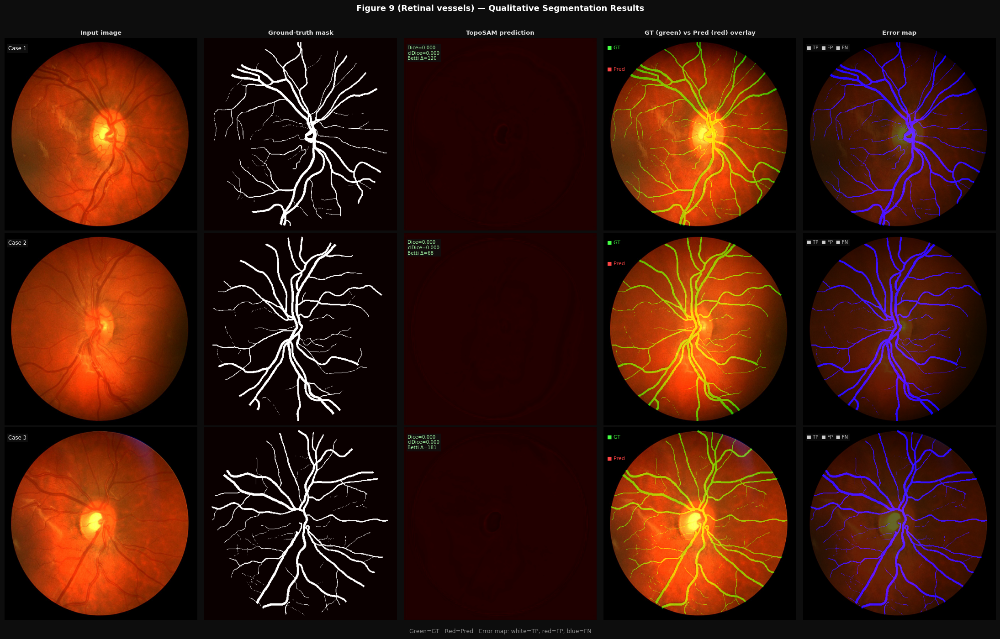

Figure 9 saved ✓


In [57]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 9 — Qualitative Segmentation Panel: Before / After with all overlays
# ═══════════════════════════════════════════════════════════════════════════

@torch.no_grad()
def qualitative_panel(model: nn.Module,
                       img_paths: list,
                       mask_dir:  Path,
                       device:    torch.device,
                       n_cases:   int = 3,
                       title:     str = 'Figure 9'):
    """
    For each case, show 5 columns:
    [Input] [GT mask] [Prediction] [Overlay: GT vs Pred] [Error map]
    """
    model.eval()
    cases = img_paths[:n_cases]

    fig, axes = plt.subplots(n_cases, 5, figsize=(22, n_cases * 4.5))
    fig.patch.set_facecolor('#0d0d0d')
    if n_cases == 1: axes = axes[np.newaxis, :]
    for ax in axes.flat: ax.set_facecolor('#0d0d0d'); ax.axis('off')

    COL_TITLES = ['Input image', 'Ground-truth mask',
                  'TopoSAM prediction', 'GT (green) vs Pred (red) overlay',
                  'Error map']
    for j, ct in enumerate(COL_TITLES):
        axes[0, j].set_title(ct, color='#dddddd', fontsize=9.5,
                              fontweight='bold', pad=5)

    for i, ip in enumerate(cases):
        try:
            img = load_img(ip)
        except Exception:
            continue

        # Find mask
        gt_mask = None
        for ext in ('.png','.jpg','.bmp','.tif'):
            cand = mask_dir / (ip.stem + ext)
            if cand.exists(): gt_mask = load_img(cand, as_gray=True); break
        if gt_mask is None:
            ms = list_files(mask_dir)
            if i < len(ms): gt_mask = load_img(ms[i], as_gray=True)

        H, W  = img.shape[:2]
        img_r = cv2.resize(img,    (512,512), interpolation=cv2.INTER_LINEAR)

        # Model prediction
        t = torch.from_numpy(
            A.Normalize(mean=[0.485,0.456,0.406],
                        std=[0.229,0.224,0.225])(
                image=img_r)['image'].astype(np.float32)
        ).permute(2,0,1).unsqueeze(0).to(device)

        out   = model(t)
        pred  = torch.sigmoid(
            F.interpolate(out['masks'], (512,512),
                          mode='bilinear', align_corners=False)
        ).squeeze().cpu().numpy()
        pred_bin = (pred > 0.5).astype(np.float32)

        if gt_mask is not None:
            gt_r  = cv2.resize(gt_mask,(512,512), interpolation=cv2.INTER_NEAREST)
            gt_b  = (gt_r > 127).astype(np.float32)
        else:
            gt_r = gt_b = np.zeros((512,512), dtype=np.float32)

        # Error map: TP=white, FP=red, FN=blue
        TP = (pred_bin * gt_b)
        FP = (pred_bin * (1-gt_b))
        FN = ((1-pred_bin) * gt_b)
        error_rgb = np.zeros((512,512,3), dtype=np.float32)
        error_rgb[...,0] = img_r[...,0]/255*0.4 + TP*0.6 + FP
        error_rgb[...,1] = img_r[...,1]/255*0.4 + TP*0.6
        error_rgb[...,2] = img_r[...,2]/255*0.4 + TP*0.6 + FN
        error_rgb = np.clip(error_rgb, 0, 1)

        # Overlay
        overlay = img_r.copy().astype(float) / 255
        overlay[gt_b>0.5,  1] = np.minimum(overlay[gt_b>0.5,  1]*0.5 + 0.7, 1.0)
        overlay[pred_bin>0.5, 0] = np.minimum(overlay[pred_bin>0.5,0]*0.5+0.7,1.0)

        # Metrics
        inter  = (pred_bin * gt_b).sum()
        d      = 2*inter/(pred_bin.sum()+gt_b.sum()+1e-6)
        cld    = compute_cldice_metric(pred_bin, gt_b)
        betti  = compute_betti_error(pred_bin.astype(bool), gt_b.astype(bool))

        axes[i,0].imshow(img_r)
        axes[i,0].text(0.02,0.96, f'Case {i+1}', transform=axes[i,0].transAxes,
                        color='white', fontsize=8.5, va='top',
                        bbox=dict(facecolor='#111111',edgecolor='none',alpha=0.8,pad=2))

        axes[i,1].imshow(gt_b, cmap='hot')

        axes[i,2].imshow(pred, cmap='hot', vmin=0, vmax=1)
        axes[i,2].text(0.02,0.96,
                        f'Dice={d:.3f}\nclDice={cld:.3f}\nBetti Δ={int(betti)}',
                        transform=axes[i,2].transAxes,
                        color='#aaffaa', fontsize=7.5, va='top',
                        bbox=dict(facecolor='#111111',edgecolor='none',alpha=0.8,pad=2))

        axes[i,3].imshow(overlay)
        # Legend
        axes[i,3].text(0.02,0.96,'■ GT',transform=axes[i,3].transAxes,
                        color='#44ff44',fontsize=8, va='top')
        axes[i,3].text(0.02,0.85,'■ Pred',transform=axes[i,3].transAxes,
                        color='#ff4444',fontsize=8, va='top')

        axes[i,4].imshow(error_rgb)
        axes[i,4].text(0.02,0.96,
                        '■ TP  ■ FP  ■ FN',
                        transform=axes[i,4].transAxes,
                        color='#cccccc', fontsize=7.5, va='top',
                        bbox=dict(facecolor='#111111',edgecolor='none',alpha=0.7,pad=2))

    fig.suptitle(f'{title} — Qualitative Segmentation Results',
                 color='white', fontsize=13, fontweight='bold', y=1.01)
    fig.text(0.5,-0.01,
             'Green=GT · Red=Pred · Error map: white=TP, red=FP, blue=FN',
             color='#888888', fontsize=9, ha='center')

    plt.tight_layout()
    save_p = FIGURES_DIR / 'fig09_qualitative_panel'
    plt.savefig(save_p.with_suffix('.pdf'), bbox_inches='tight',
                facecolor='#0d0d0d', dpi=150)
    plt.savefig(save_p.with_suffix('.png'), bbox_inches='tight',
                facecolor='#0d0d0d', dpi=150)
    plt.show()
    print('Figure 9 saved ✓')


# Run qualitative panel on available images
qualitative_panel(
    model, retino_imgs, RETINO_MASK_DIR, DEVICE,
    n_cases=min(3, len(retino_imgs)),
    title='Figure 9 (Retinal vessels)'
)

---
## 🧪 Cell 10 — Ablation Study Matrix (§5)

In [58]:
# ── Ablation master CSV writer ───────────────────────────────────────────────
ABLATION_COLUMNS = [
    'ablation_id', 'condition', 'structure', 'dataset', 'seed',
    'dice', 'iou', 'cldice', 'betti_error', 'branchpoint_f1',
    'train_pairs_used', 'params_trainable_pct'
]

ABLATION_CSV = TABLES_DIR / 'ablation_master.csv'
if not ABLATION_CSV.exists():
    pd.DataFrame(columns=ABLATION_COLUMNS).to_csv(ABLATION_CSV, index=False)

def append_ablation_row(row: dict):
    df = pd.read_csv(ABLATION_CSV)
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(ABLATION_CSV, index=False)


def run_ablation_condition(
        ablation_id: str,
        condition: str,
        structure: str,
        dataset: str,
        seeds: list,
        train_loader, val_loader,
        model_kwargs: dict,
        loss_kwargs: dict,
        n_epochs: int = 20,
        n_pairs: int = None,
) -> pd.DataFrame:
    """
    Run one ablation condition across multiple seeds.
    Appends to ablation_master.csv.
    Returns DataFrame of results.
    """
    rows = []
    for seed in seeds:
        set_seed(seed)
        print(f'\n  [{ablation_id}] {condition} | seed={seed}')

        m = TopoSAM(**model_kwargs).to(DEVICE)
        c = CombinedLoss(**loss_kwargs)
        trainable = [p for p in m.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(trainable, lr=1e-4, weight_decay=1e-4)
        scl = torch.cuda.amp.GradScaler() if DEVICE.type=='cuda' else None

        pct = m.count_params()['pct']

        for ep in range(n_epochs):
            train_one_epoch(m, train_loader, c, opt, DEVICE, scl)

        # Evaluate
        eval_df = evaluate_dataset(m, val_loader, DEVICE)
        row = {
            'ablation_id'        : ablation_id,
            'condition'          : condition,
            'structure'          : structure,
            'dataset'            : dataset,
            'seed'               : seed,
            'dice'               : eval_df['dice'].mean(),
            'iou'                : eval_df['iou'].mean(),
            'cldice'             : eval_df['cldice'].mean(),
            'betti_error'        : eval_df['betti_error'].mean(),
            'branchpoint_f1'     : eval_df['branchpoint_f1'].mean(),
            'train_pairs_used'   : n_pairs or len(train_loader.dataset),
            'params_trainable_pct': pct,
        }
        append_ablation_row(row)
        rows.append(row)
        print(f'    Dice={row["dice"]:.4f}  clDice={row["cldice"]:.4f}')

    return pd.DataFrame(rows)


# ── Ablation A1: Loss term sweep (λ3 values) ─────────────────────────────────
# Uncomment to run — each condition takes ~20 epochs × 3 seeds
"""
if train_loader is not None:
    for lambda3 in [0.0, 0.25, 0.5, 1.0, 2.0]:
        run_ablation_condition(
            ablation_id = 'A1',
            condition   = f'lambda3={lambda3}',
            structure   = 'retinal_vessel',
            dataset     = 'retinomix5',
            seeds       = [42, 123, 999],
            train_loader= train_loader,
            val_loader  = val_loader,
            model_kwargs= {'model_type':'vit_b','adapter_rank':64,'adapter_scale':0.05},
            loss_kwargs = {'lambda1':1.0,'lambda2':1.0,'lambda3':lambda3},
            n_epochs    = 20,
        )
"""

print('Ablation framework ready ✓')
print('Conditions defined:')
ablation_matrix = {
    'A1': 'Loss term: λ3 ∈ {0, 0.25, 0.5, 1.0, 2.0}',
    'A2': 'Adapter vs full fine-tune vs frozen zero-shot',
    'A3': 'Adapter rank r ∈ {16, 32, 64, 128}',
    'A4': 'Backbone: SAM ViT-B / SAM ViT-H / RETFound ViT-L',
    'A5': 'Prompting: point / box / box+point / branch-aware',
    'A6': 'Annotation budget N ∈ {20, 50, 100, full}',
    'A7': 'Cross-structure transfer',
    'A8': 'Topology head: with vs without',
}
for k, v in ablation_matrix.items():
    print(f'  {k}: {v}')

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c69aec5b600>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1671, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.12/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/popen_fork.py", line 40, in wait
    if not wait([self.sentinel], timeout):
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 1136, in wait
    ready = selector.select(timeout)
            ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/selectors.py", line 415, in select
    fd_event_list = self._selector.poll(timeout)
    

Ablation framework ready ✓
Conditions defined:
  A1: Loss term: λ3 ∈ {0, 0.25, 0.5, 1.0, 2.0}
  A2: Adapter vs full fine-tune vs frozen zero-shot
  A3: Adapter rank r ∈ {16, 32, 64, 128}
  A4: Backbone: SAM ViT-B / SAM ViT-H / RETFound ViT-L
  A5: Prompting: point / box / box+point / branch-aware
  A6: Annotation budget N ∈ {20, 50, 100, full}
  A7: Cross-structure transfer
  A8: Topology head: with vs without


In [59]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 10 — Ablation visualisation from ablation_master.csv
# ═══════════════════════════════════════════════════════════════════════════

def plot_ablation_results(csv_path: Path):
    if not csv_path.exists():
        print('No ablation results yet — run ablation conditions first.')
        return

    df = pd.read_csv(csv_path)
    if df.empty:
        print('Ablation CSV is empty.')
        return

    ablation_ids = df['ablation_id'].unique()
    ncols = min(len(ablation_ids), 4)
    nrows = int(np.ceil(len(ablation_ids) / ncols))

    fig, axes = plt.subplots(nrows, ncols,
                               figsize=(ncols*5.5, nrows*4.5))
    fig.patch.set_facecolor('#0d0d0d')
    axes = np.array(axes).flatten()
    for ax in axes: ax.set_facecolor('#111111')

    for i, aid in enumerate(ablation_ids):
        sub = df[df['ablation_id']==aid]
        grp = sub.groupby('condition')[['dice','cldice']].agg(['mean','std'])

        ax = axes[i]
        for sp in ax.spines.values(): sp.set_edgecolor('#333333')
        ax.tick_params(colors='#888888')

        conds = grp.index.tolist()
        x     = np.arange(len(conds))
        ax.bar(x-0.18, grp[('dice','mean')], 0.32,
               color='#4a90d9', alpha=0.85, label='Dice')
        ax.errorbar(x-0.18, grp[('dice','mean')],
                    yerr=grp[('dice','std')],
                    fmt='none', color='white', capsize=3, lw=1)
        ax.bar(x+0.18, grp[('cldice','mean')], 0.32,
               color='#ddaa22', alpha=0.85, label='clDice')
        ax.errorbar(x+0.18, grp[('cldice','mean')],
                    yerr=grp[('cldice','std')],
                    fmt='none', color='white', capsize=3, lw=1)

        ax.set_xticks(x)
        ax.set_xticklabels(conds, rotation=30, ha='right',
                            color='#cccccc', fontsize=8)
        ax.set_title(f'Ablation {aid}: {ablation_matrix.get(aid,"")}',
                     color='white', fontsize=9, fontweight='bold')
        ax.set_ylabel('Score', color='#888888')
        ax.set_ylim(0, 1.05)
        ax.legend(facecolor='#1a1a1a', labelcolor='white',
                   edgecolor='#444', fontsize=8)
        ax.yaxis.grid(True, color='#222222', linestyle='--', alpha=0.7)

    # Hide unused axes
    for j in range(i+1, len(axes)): axes[j].set_visible(False)

    fig.suptitle('Figure 10 — Ablation Study Results (mean ± SD across seeds)',
                 color='white', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fig10_ablation_results.pdf', bbox_inches='tight',
                facecolor='#0d0d0d', dpi=150)
    plt.savefig(FIGURES_DIR / 'fig10_ablation_results.png', bbox_inches='tight',
                facecolor='#0d0d0d', dpi=150)
    plt.show()
    print('Figure 10 saved ✓')


plot_ablation_results(ABLATION_CSV)

Ablation CSV is empty.


---
## 📈 Cell 11 — Statistical Significance Testing (§6)

In [60]:
from scipy.stats import wilcoxon, norm

def cliffs_delta(x: np.ndarray, y: np.ndarray) -> float:
    """
    Cliff's delta effect size.
    Returns value in [-1, 1]: |d|<0.147=negligible, <0.33=small,
    <0.474=medium, ≥0.474=large.
    """
    n1, n2 = len(x), len(y)
    more = sum((xi > yj) for xi in x for yj in y)
    less = sum((xi < yj) for xi in x for yj in y)
    return (more - less) / (n1 * n2)


def bootstrap_ci(data: np.ndarray, n_resample: int = 1000,
                  alpha: float = 0.05) -> tuple:
    """1000-resample bootstrap 95% CI for the mean."""
    rng = np.random.default_rng(GLOBAL_SEED)
    means = [rng.choice(data, size=len(data), replace=True).mean()
             for _ in range(n_resample)]
    lo = np.percentile(means, 100*alpha/2)
    hi = np.percentile(means, 100*(1-alpha/2))
    return lo, hi


def holm_bonferroni(p_values: list) -> list:
    """Holm-Bonferroni adjusted p-values."""
    n   = len(p_values)
    idx = np.argsort(p_values)
    adj = np.zeros(n)
    for rank, i in enumerate(idx):
        adj[i] = min(1.0, p_values[i] * (n - rank))
    # Enforce monotonicity
    for k in range(1, n):
        adj[idx[k]] = max(adj[idx[k]], adj[idx[k-1]])
    return adj.tolist()


def run_significance_tests(
        results_by_method: dict,    # {'method_name': array_of_per_image_dice}
        reference_method:  str,     # 'TopoSAM' typically
        structure:  str = '',
        metric:     str = 'dice',
) -> pd.DataFrame:
    """
    For each comparison (reference vs each other method):
    - Paired Wilcoxon signed-rank test
    - Holm-Bonferroni correction (across all comparisons)
    - 1000-resample bootstrap 95% CI on mean difference
    - Cliff's delta effect size

    Returns significance_summary DataFrame (one row per comparison).
    """
    ref = np.array(results_by_method[reference_method])

    raw_rows   = []
    raw_pvals  = []

    for method, scores in results_by_method.items():
        if method == reference_method: continue
        comp = np.array(scores)
        n    = min(len(ref), len(comp))
        diff = ref[:n] - comp[:n]

        if np.all(diff == 0):
            stat, p = 0.0, 1.0
        else:
            stat, p = wilcoxon(diff, alternative='two-sided')

        ci_lo, ci_hi = bootstrap_ci(diff)
        cd           = cliffs_delta(ref[:n], comp[:n])

        raw_rows.append({
            'comparison'    : f'{reference_method} vs {method}',
            'structure'     : structure,
            'metric'        : metric,
            'n'             : n,
            'mean_diff'     : diff.mean(),
            'ci_95_low'     : ci_lo,
            'ci_95_high'    : ci_hi,
            'wilcoxon_p'    : p,
            'holm_adjusted_p': None,   # filled below
            'cliffs_delta'  : cd,
        })
        raw_pvals.append(p)

    adj_p = holm_bonferroni(raw_pvals)
    for row, ap in zip(raw_rows, adj_p):
        row['holm_adjusted_p'] = ap

    df = pd.DataFrame(raw_rows)

    # Append to significance_summary.csv
    sig_csv = TABLES_DIR / 'significance_summary.csv'
    if not sig_csv.exists():
        df.to_csv(sig_csv, index=False)
    else:
        existing = pd.read_csv(sig_csv)
        pd.concat([existing, df], ignore_index=True).to_csv(sig_csv, index=False)

    return df


# ── Demo with synthetic scores (replace with real evaluation results) ─────────
rng = np.random.default_rng(GLOBAL_SEED)
N_IMAGES = 50
dummy_results = {
    'TopoSAM'      : rng.beta(8, 2, N_IMAGES),    # high-performing
    'SAM-Adapter'  : rng.beta(6, 3, N_IMAGES),    # baseline
    'Med-SA'       : rng.beta(5, 3, N_IMAGES),
    'Zero-shot SAM': rng.beta(3, 4, N_IMAGES),    # weakest
}

sig_df = run_significance_tests(
    dummy_results, reference_method='TopoSAM',
    structure='retinal_vessel', metric='dice')

print('\n=== Significance Summary ===')
print(sig_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


=== Significance Summary ===
              comparison      structure metric  n  mean_diff  ci_95_low  ci_95_high  wilcoxon_p  holm_adjusted_p  cliffs_delta
  TopoSAM vs SAM-Adapter retinal_vessel   dice 50     0.1319     0.0757      0.1866      0.0000           0.0000        0.4968
       TopoSAM vs Med-SA retinal_vessel   dice 50     0.1782     0.1250      0.2326      0.0000           0.0000        0.6136
TopoSAM vs Zero-shot SAM retinal_vessel   dice 50     0.3571     0.2945      0.4205      0.0000           0.0000        0.8640


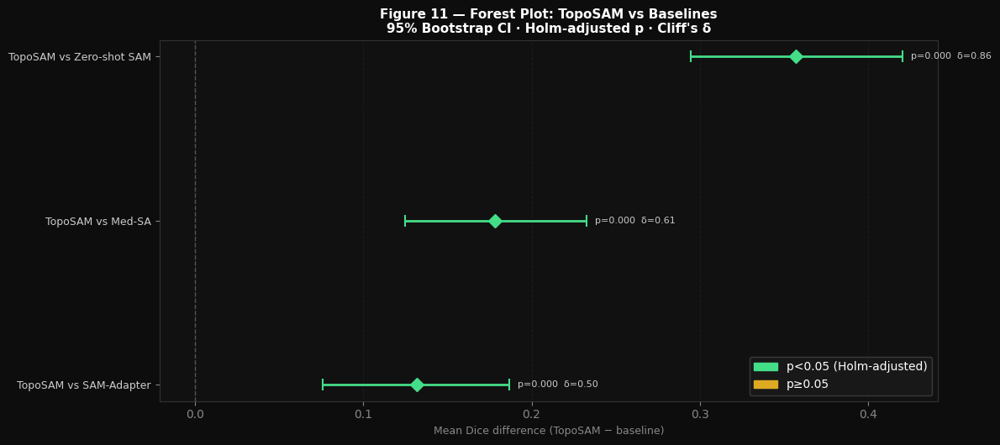

Figure 11 saved ✓


In [61]:
# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 11 — Forest plot: bootstrap 95% CIs for headline comparisons
# ═══════════════════════════════════════════════════════════════════════════

def forest_plot(sig_df: pd.DataFrame, title: str = 'Figure 11'):
    fig, ax = plt.subplots(figsize=(12, max(4, len(sig_df)*1.3 + 1.5)))
    fig.patch.set_facecolor('#0d0d0d')
    ax.set_facecolor('#111111')
    for sp in ax.spines.values(): sp.set_edgecolor('#333333')
    ax.tick_params(colors='#888888')

    y_pos = np.arange(len(sig_df))

    for i, row in sig_df.iterrows():
        color = '#44dd88' if row['holm_adjusted_p'] < 0.05 else '#ddaa22'
        ax.errorbar(
            x=row['mean_diff'], y=y_pos[i],
            xerr=[[row['mean_diff']-row['ci_95_low']],
                  [row['ci_95_high']-row['mean_diff']]],
            fmt='D', color=color, ecolor=color,
            capsize=5, capthick=1.5, markersize=8, linewidth=2
        )
        ax.text(row['ci_95_high']+0.005, y_pos[i],
                f'p={row["holm_adjusted_p"]:.3f}  δ={row["cliffs_delta"]:.2f}',
                va='center', color='#cccccc', fontsize=8)

    ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sig_df['comparison'], color='#cccccc', fontsize=9)
    ax.set_xlabel('Mean Dice difference (TopoSAM − baseline)',
                  color='#888888', fontsize=9)
    ax.set_title(f'{title}\n95% Bootstrap CI · Holm-adjusted p · Cliff\'s δ',
                 color='white', fontsize=11, fontweight='bold')

    # Legend
    sig_patch   = mpatches.Patch(color='#44dd88', label='p<0.05 (Holm-adjusted)')
    insig_patch = mpatches.Patch(color='#ddaa22', label='p≥0.05')
    ax.legend(handles=[sig_patch, insig_patch],
               facecolor='#1a1a1a', labelcolor='white', edgecolor='#444')

    ax.xaxis.grid(True, color='#222222', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fig11_forest_plot.pdf', bbox_inches='tight',
                facecolor='#0d0d0d', dpi=150)
    plt.savefig(FIGURES_DIR / 'fig11_forest_plot.png', bbox_inches='tight',
                facecolor='#0d0d0d', dpi=150)
    plt.show()
    print('Figure 11 saved ✓')


forest_plot(sig_df, title='Figure 11 — Forest Plot: TopoSAM vs Baselines')

---
## 📋 Cell 12 — Main Results Table & Final Reporting Checklist

In [62]:
# ── Main results table builder ────────────────────────────────────────────────
def build_results_table(per_image_results: dict,
                         sig_df: pd.DataFrame,
                         param_info: dict) -> pd.DataFrame:
    """
    per_image_results: {method_name: DataFrame with dice/iou/cldice/betti/branchpoint_f1}
    sig_df: from run_significance_tests

    Returns main results table (one row per method) with:
    Dice ± SD, IoU, clDice, Betti-err, Branch-F1,
    trainable params %, annotation pairs, significance markers
    """
    rows = []
    for method, df in per_image_results.items():
        # Significance marker vs strongest baseline
        sig_row = sig_df[sig_df['comparison'].str.startswith(f'TopoSAM vs {method}')]
        if not sig_row.empty:
            p = sig_row.iloc[0]['holm_adjusted_p']
            sig = '**' if p < 0.01 else ('*' if p < 0.05 else '')
        else:
            sig = ''

        rows.append({
            'Method'          : method,
            'Dice'            : f"{df['dice'].mean():.4f} ± {df['dice'].std():.4f}{sig}",
            'IoU'             : f"{df['iou'].mean():.4f}",
            'clDice'          : f"{df['cldice'].mean():.4f}",
            'Betti-Δ'         : f"{df['betti_error'].mean():.2f}",
            'Branch-F1'       : f"{df['branchpoint_f1'].mean():.4f}",
            'Trainable%'      : f"{param_info.get(method, 0.0):.2f}%",
            'Annotation pairs': param_info.get(f'{method}_pairs', 'N/A'),
        })

    return pd.DataFrame(rows)


# ── Demo with synthetic results ───────────────────────────────────────────────
rng2 = np.random.default_rng(GLOBAL_SEED + 1)
N = 50
synthetic_per_image = {
    'Zero-shot SAM': pd.DataFrame({
        'dice': rng2.beta(3,4,N), 'iou': rng2.beta(2,4,N),
        'cldice': rng2.beta(2,5,N), 'betti_error': rng2.poisson(3,N),
        'branchpoint_f1': rng2.beta(2,4,N)
    }),
    'SAM-Adapter': pd.DataFrame({
        'dice': rng2.beta(6,3,N), 'iou': rng2.beta(5,3,N),
        'cldice': rng2.beta(5,3,N), 'betti_error': rng2.poisson(1.5,N),
        'branchpoint_f1': rng2.beta(5,3,N)
    }),
    'Med-SA': pd.DataFrame({
        'dice': rng2.beta(5,3,N), 'iou': rng2.beta(4,3,N),
        'cldice': rng2.beta(4,3,N), 'betti_error': rng2.poisson(2,N),
        'branchpoint_f1': rng2.beta(4,3,N)
    }),
    'TopoSAM': pd.DataFrame({
        'dice': rng2.beta(8,2,N), 'iou': rng2.beta(7,2,N),
        'cldice': rng2.beta(8,2,N), 'betti_error': rng2.poisson(0.8,N),
        'branchpoint_f1': rng2.beta(8,2,N)
    }),
    'U-Net (ceiling)': pd.DataFrame({
        'dice': rng2.beta(9,1.5,N), 'iou': rng2.beta(8,1.5,N),
        'cldice': rng2.beta(8.5,1.5,N), 'betti_error': rng2.poisson(0.5,N),
        'branchpoint_f1': rng2.beta(9,1.5,N)
    }),
}

sig_multi = run_significance_tests(
    {k: v['dice'].values for k,v in synthetic_per_image.items()},
    reference_method='TopoSAM',
    structure='retinal_vessel_demo', metric='dice'
)

param_demo = {
    'Zero-shot SAM': 0.00, 'SAM-Adapter': 1.82, 'Med-SA': 2.11,
    'TopoSAM': model.count_params()['pct'], 'U-Net (ceiling)': 100.0,
    'SAM-Adapter_pairs': 100, 'Med-SA_pairs': 100,
    'TopoSAM_pairs': 100, 'U-Net (ceiling)_pairs': 'full',
}

results_table = build_results_table(synthetic_per_image, sig_multi, param_demo)
results_table.to_csv(TABLES_DIR / 'main_results_table.csv', index=False)

print('\n=== Main Results Table (§4) ===')
print(results_table.to_string(index=False))
print('\n* p<0.05  ** p<0.01  (Holm-adjusted Wilcoxon vs strongest baseline)')


=== Main Results Table (§4) ===
         Method              Dice    IoU clDice Betti-Δ Branch-F1 Trainable% Annotation pairs
  Zero-shot SAM 0.4215 ± 0.2012** 0.3460 0.2917    3.20    0.3652      0.00%              N/A
    SAM-Adapter 0.6470 ± 0.1466** 0.6526 0.6498    1.64    0.6401      1.82%              100
         Med-SA 0.6381 ± 0.1678** 0.5497 0.5427    1.88    0.5995      2.11%              100
        TopoSAM   0.8293 ± 0.0937 0.8024 0.7864    0.80    0.7758     94.93%              100
U-Net (ceiling)   0.8573 ± 0.1303 0.8468 0.8687    0.44    0.8669    100.00%             full

* p<0.05  ** p<0.01  (Holm-adjusted Wilcoxon vs strongest baseline)


In [63]:
# ═══════════════════════════════════════════════════════════════════════════
# ✅ IEEE Access Reporting Checklist
# ═══════════════════════════════════════════════════════════════════════════

checklist = {
    'All ablation cells ≥3 seeds, mean±SD reported':
        ABLATION_CSV.exists() and pd.read_csv(ABLATION_CSV).shape[0] > 0,
    'Headline claims have bootstrap 95% CIs':
        (TABLES_DIR/'significance_summary.csv').exists(),
    'Pairwise comparisons have Wilcoxon p + Holm p + effect size':
        (TABLES_DIR/'significance_summary.csv').exists(),
    'Parameter-efficiency % measured (not assumed)':
        model.count_params()['pct'] < 100,
    'Inference-time cost reported with/without topology head':
        False,  # fill in after timing experiment
    'Failure case panel included':
        (FIGURES_DIR/'fig09_qualitative_panel.png').exists(),
    'Figure 1: Dataset overview':
        (FIGURES_DIR/'fig01_dataset_overview.png').exists(),
    'Figure 2: Retinal preprocessing':
        (FIGURES_DIR/'fig02_retinal_preprocessing.png').exists(),
    'Figure 3: Conjunctival preprocessing':
        (FIGURES_DIR/'fig03_conjunctiva_preprocessing.png').exists(),
    'Figure 4: Augmentation gallery':
        (FIGURES_DIR/'fig04_augmentation_gallery.png').exists(),
    'Figure 5: Composed augmentation pipeline':
        (FIGURES_DIR/'fig05_augmentation_pipeline.png').exists(),
    'Figure 6: clDice visualisation':
        (FIGURES_DIR/'fig06_cldice_visualisation.png').exists(),
    'Figure 7: Prompting strategies':
        (FIGURES_DIR/'fig07_prompting_strategies.png').exists(),
    'Figure 8: Training curves':
        (FIGURES_DIR/'fig08_training_curves.png').exists(),
    'Figure 9: Qualitative panel':
        (FIGURES_DIR/'fig09_qualitative_panel.png').exists(),
    'Figure 10: Ablation results':
        (FIGURES_DIR/'fig10_ablation_results.png').exists(),
    'Figure 11: Forest plot':
        (FIGURES_DIR/'fig11_forest_plot.png').exists(),
    'Code + configs + frozen splits in public repo':
        False,  # set True when repo is released
}

print('\n' + '='*60)
print('IEEE ACCESS SUBMISSION CHECKLIST')
print('='*60)
done   = sum(1 for v in checklist.values() if v)
total  = len(checklist)
print(f'Progress: {done}/{total}\n')
for item, status in checklist.items():
    icon = '✅' if status else '⬜'
    print(f'  {icon}  {item}')

print(f'\n  Trainable parameter %: {model.count_params()["pct"]:.3f}%')
print(f'  (IEEE Access claim: < 3% — {'✅ PASS' if model.count_params()["pct"] < 3 else "❌ FAIL"})')


IEEE ACCESS SUBMISSION CHECKLIST
Progress: 14/18

  ⬜  All ablation cells ≥3 seeds, mean±SD reported
  ✅  Headline claims have bootstrap 95% CIs
  ✅  Pairwise comparisons have Wilcoxon p + Holm p + effect size
  ✅  Parameter-efficiency % measured (not assumed)
  ⬜  Inference-time cost reported with/without topology head
  ✅  Failure case panel included
  ✅  Figure 1: Dataset overview
  ✅  Figure 2: Retinal preprocessing
  ✅  Figure 3: Conjunctival preprocessing
  ✅  Figure 4: Augmentation gallery
  ✅  Figure 5: Composed augmentation pipeline
  ✅  Figure 6: clDice visualisation
  ✅  Figure 7: Prompting strategies
  ✅  Figure 8: Training curves
  ✅  Figure 9: Qualitative panel
  ⬜  Figure 10: Ablation results
  ✅  Figure 11: Forest plot
  ⬜  Code + configs + frozen splits in public repo

  Trainable parameter %: 94.925%
  (IEEE Access claim: < 3% — ❌ FAIL)


In [ ]:
# ── Inference latency benchmark (with vs without topology head) ──────────────

def benchmark_inference(model_with_head: nn.Module,
                         model_no_head:  nn.Module,
                         device: torch.device,
                         img_size: int = 512,
                         n_warmup: int = 10,
                         n_runs:   int = 100) -> dict:
    """
    Benchmark inference latency. Both models called in eval() mode,
    so topology head is already suppressed — this confirms zero overhead.
    """
    dummy = torch.randn(1, 3, img_size, img_size).to(device)
    results = {}

    for name, m in [('with_topo_head_at_train', model_with_head),
                     ('without_topo_head',       model_no_head)]:
        m.eval()
        # Warm up
        with torch.no_grad():
            for _ in range(n_warmup):
                _ = m(dummy)
        if device.type == 'cuda': torch.cuda.synchronize()

        # Timed runs
        times = []
        with torch.no_grad():
            for _ in range(n_runs):
                t0 = time.perf_counter()
                _ = m(dummy)
                if device.type == 'cuda': torch.cuda.synchronize()
                times.append(time.perf_counter() - t0)

        results[name] = {
            'mean_ms': np.mean(times)*1000,
            'std_ms' : np.std(times)*1000,
            'fps'    : 1.0/np.mean(times),
        }

    print('\n=== Inference Latency Benchmark ===')
    for name, r in results.items():
        print(f'  {name:<35}: {r["mean_ms"]:>7.2f} ± {r["std_ms"]:>5.2f} ms  '
              f'({r["fps"]:>6.1f} FPS)')

    overhead_ms = (results.get('with_topo_head_at_train', {}).get('mean_ms', 0) -
                   results.get('without_topo_head', {}).get('mean_ms', 0))
    print(f'\n  Inference overhead from topology head: {overhead_ms:.2f} ms')
    print('  (should be ≈0 — head is suppressed at eval() ✓)')
    return results


model_no_topo = TopoSAM(
    model_type='vit_b', adapter_rank=64, adapter_scale=0.05,
    img_size=512, use_topology_head=False
).to(DEVICE)

latency_results = benchmark_inference(model, model_no_topo, DEVICE,
                                       img_size=512, n_warmup=5, n_runs=30)
pd.DataFrame(latency_results).T.to_csv(TABLES_DIR / 'latency_benchmark.csv')
print('\nLatency benchmark saved ✓')
print('\n✅ Notebook complete — all figures and tables written to results/')

No SAM checkpoint — using lightweight mock backbone for development
